# Random Surfer: From Network Structure to Visit Frequencies

How can links help us identify important web pages? PageRank builds
on the idea that a page matters when other important pages point to it.
The random surfer gives this idea a practical interpretation:
a visitor repeatedly follows a randomly selected outgoing link,
and pages visited more frequently receive a higher ranking.

This notebook investigates when this process produces a stable ranking
and what can prevent it. We compare results from matrix calculations,
probability updates, and simulated visits, using four six-page networks
and a real web network. The accompanying essay develops the theoretical
background.


## Model and Method

We describe the network through a matrix P, where $P_{ij}$ is the
probability of moving from page j to page i. Columns therefore describe
outgoing probabilities. The surfer chooses uniformly among available
links. Self-links are excluded from the original networks to focus
on connections between different pages.

Our target is a stationary distribution: a probability vector $\pi$
satisfying $P\pi=\pi$. We compute it by normalizing a nonnegative right
eigenvector associated with +1. Its existence, however, does not
automatically guarantee convergence to it.

Three properties provide progressively stronger guarantees:

| Property | Meaning and guarantee |
|---|---|
| **Stochasticity** | Entries are nonnegative and each column sums to one. Probability is preserved, the spectral radius is one, and at least one stationary distribution exists. |
| **Irreducibility** | Every page is reachable from every other page. Together with stochasticity, this guarantees a unique, strictly positive stationary distribution and a simple eigenvalue +1. |
| **Aperiodicity** | Return times have no common divisor greater than one. Together with the previous properties, this guarantees convergence from any initial distribution; all other eigenvalues have modulus below one. |

Perron–Frobenius theory provides the basis for these guarantees.
For finite networks, irreducibility and aperiodicity together are
equivalent to **primitivity**, which means some power of P is strictly positive.
Our code checks this condition. Some guarantees may still hold
without primitivity, as the examples illustrate.


### Problems and Corrections

We examine three obstacles: **dangling pages**, with no outgoing links;
**closed groups**, from which the surfer cannot escape; and
**periodicity**, which can cause persistent probability oscillations.

We first restore stochasticity by replacing dangling columns with
uniform probabilities $1/n$. To address trapping and periodicity,
we introduce teleportation from every page. Starting from a stochastic
matrix S, the Google matrix is

$$
G=\alpha S+(1-\alpha)\frac{\mathbf{1}\mathbf{1}^{\top}}{n},
\qquad \alpha=0.85.
$$

The surfer uses S with probability 0.85 and selects any page uniformly
with probability 0.15, including its current page. G is stochastic
and strictly positive, hence primitive. The dangling correction must
come first: teleportation alone does not make a zero column sum to one.

### Analytical Approach

We study each network in three complementary ways, comparing
the mathematical prediction with its evolution over time and
with simulated behaviour:

1. **Eigenvalue analysis:** we compute the eigenvalues and, when
   available, the stationary distribution. This gives the theoretical
   reference and helps explain whether convergence is expected.

2. **Probability iteration:** starting from a chosen distribution,
   we repeatedly apply $x_{t+1}=Px_t$. This shows how the probabilities
   evolve under the model: they may approach the stationary
   distribution, oscillate, or lose mass through dangling columns.

3. **Random-surfer simulation:** when the matrix is stochastic,
   we simulate individual visits and compare their relative
   frequencies with the stationary distribution. This provides
   a simulation-based check of the theoretical prediction.

These methods describe related but distinct quantities.
Probability iteration tracks the distribution at each step;
simulation records one path and accumulates visits over time.
For this reason, periodic probabilities may oscillate even
when visit frequencies approach the stationary distribution.

The four six-page examples make these mechanisms easy to observe.
We begin with a primitive network, then introduce dangling pages,
an aperiodic closed group, and a periodic closed group.
Where corrections are needed, we compare the results before
and after applying them.

The final example applies the same approach to a real web network.
With 500 pages, we adapt the presentation: we summarize the eigenvalues, track total probability before correction,
and measure distance from the stationary distribution afterwards.
We then compare simulated frequencies with stationary probabilities
and examine the highest-ranked pages.


## Importing Libraries

We use NumPy for matrix calculations and random sampling, pandas
and `display` for tables, and Matplotlib for plots. In the real-network
example, `scipy.io` loads the dataset from a MATLAB file, while
`warnings` manages a warning during loading.

In [ ]:
%pip install numpy pandas matplotlib scipy networkx ipython

In [199]:
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import scipy.io
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
import networkx as nx
import warnings

## Shared Functions

The functions below implement the steps of this analysis.
We define them once and reuse them through short calls in
the examples. Each function displays its relevant results
and returns values that can be saved for later comparisons.
Comparison tables remain separate from the functions.

### Drawing the Network

We use `plot_network(P, title)` to display the network as a directed
graph using NetworkX and Matplotlib. Nodes are labeled by page number
and arranged in a circle.

An arrow from page j to page i is drawn whenever P[i, j] > 0.
Thicker arrows indicate higher transition probabilities, using the
same thickness scale across graphs to make comparisons easier.

In [200]:
def plot_network(P, title="Web network"):
    n = P.shape[0]

    graph = nx.DiGraph()
    graph.add_nodes_from(range(1, n + 1))

    for j in range(n):
        for i in range(n):
            if P[i, j] > 0:
                graph.add_edge(j + 1, i + 1, weight=P[i, j])

    widths = [
        0.3 + 4 * graph[u][v]["weight"]
        for u, v in graph.edges()
    ]

    positions = nx.circular_layout(graph)

    plt.figure(figsize=(7, 7))

    nx.draw_networkx(
        graph,
        pos=positions,
        node_color="lightblue",
        node_size=900,
        font_size=12,
        arrows=True,
        arrowsize=20,
        width=widths,
        connectionstyle="arc3,rad=0.15"
    )

    plt.title(title)
    plt.axis("off")
    plt.show()

### Checking Primitivity

We use `check_primitivity(P)` to check whether a stochastic matrix
guarantees a unique, strictly positive stationary distribution
that probability updates approach from any starting distribution.

The function examines successive powers of P. If it finds one
with all entries strictly positive, it displays the first exponent
and the corresponding matrix, returning `(k, P_power)`.
Otherwise, it returns `(None, None)`.

The default limit of 100 powers is sufficient for our six-page
networks, since Wielandt's bound is 26. For larger networks,
an unsuccessful search may be inconclusive. The function checks
P without changing it.
With `show=False`, the function returns its results without displaying them.


In [201]:
def check_primitivity(P, max_steps=100, show=True):
    P_power = P.copy()

    for k in range(1, max_steps + 1):
        if np.all(P_power > 0):
            if show:
                print("The matrix is primitive.")
                print("First strictly positive power:", k)
                print(P_power.round(4))

            return k, P_power

        P_power = P_power @ P

    if show:
        print("No strictly positive power found within", max_steps, "steps.")

        if max_steps >= (P.shape[0] - 1)**2 + 1:
            print("The matrix is not primitive.")
        else:
            print("The search limit is insufficient to conclude.")

    return None, None


### Eigenvalues and Stationary Distributions

We use `eigen_analysis(P)` to compute the eigenvalues and inspect
their absolute values. A stationary distribution is a nonnegative
vector associated with the eigenvalue +1, normalized to sum to one.

If +1 is simple, the function normalizes its eigenvector and returns
`(eigenvalues, pi)`. If +1 is absent, it reports that no stationary
distribution exists and returns `(eigenvalues, None)`.

If +1 has multiplicity greater than one, the function identifies
the closed communicating groups and computes one stationary
distribution for each group, assigning zero probability outside it.
It displays these vectors and returns them as columns of a matrix.
Every convex combination of these distributions is also stationary,
so there is no unique stationary distribution.

With `show=False`, the function returns its results without displaying them.

In [202]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components


def eigen_analysis(P, show=True):
    eigenvalues, eigenvectors = np.linalg.eig(P)

    if show:
        print("Eigenvalues:")
        print(eigenvalues.round(4))

        print("Absolute values of eigenvalues:")
        print(np.abs(eigenvalues).round(4))

    indices = np.where(np.abs(eigenvalues - 1) < 1e-8)[0]

    # No eigenvalue +1
    if len(indices) == 0:
        if show:
            print("No eigenvalue +1: no stationary distribution.")

        return eigenvalues, None

    # Simple eigenvalue +1: same calculation as before
    if len(indices) == 1:
        pi = eigenvectors[:, indices[0]].real
        pi = pi / pi.sum()

        if show:
            print("Stationary distribution:")
            print(pi.round(4))

        return eigenvalues, pi

    # Multiple eigenvalue +1: identify the closed groups
    n = P.shape[0]

    n_groups, labels = connected_components(
        csr_matrix(P.T > 0),
        directed=True,
        connection="strong"
    )

    distributions = []

    for group in range(n_groups):
        pages = np.where(labels == group)[0]
        outside = np.where(labels != group)[0]

        # A closed group has no outgoing links to outside pages
        if np.any(P[np.ix_(outside, pages)] > 0):
            continue

        submatrix = P[np.ix_(pages, pages)]
        values, vectors = np.linalg.eig(submatrix)

        index = np.argmin(np.abs(values - 1))
        local_pi = vectors[:, index].real
        local_pi = local_pi / local_pi.sum()

        pi = np.zeros(n)
        pi[pages] = local_pi

        distributions.append(pi)

    stationary_vectors = np.column_stack(distributions)

    if show:
        print("No unique stationary distribution.")

        for j in range(stationary_vectors.shape[1]):
            print("Stationary distribution", j + 1, ":")
            print(stationary_vectors[:, j].round(4))

        print(
            "Every convex combination of these vectors "
            "is also a stationary distribution."
        )

    return eigenvalues, stationary_vectors

### Tracking Page Probabilities

We use `iterate_probabilities(P, x0, n_steps, title)` to follow the updates

$$x_{t+1}=Px_t, \qquad x_t=P^t x_0.$$

Each page passes its probability to the destinations specified by its column of P. The function plots each page's probability and returns `history`, containing the initial distribution and every update, for comparison tables.

To compare two matrices in one graph, we first use `show=False`, then `new_figure=False`. The `style` and `label` options distinguish the curves; each page keeps the same colour.

The function also accepts dangling columns, allowing us to observe probability loss. With `total=True`, it plots the total probability $m_t=\sum_i x_{t,i}$ instead of individual page curves, which is useful for the 500-page network.

With `plot=False`, the function returns the probability history
without creating a graph. This allows us to use the results
for other plots, such as the distance from equilibrium.


In [203]:
def iterate_probabilities(P, x0, n_steps, title="",
                          new_figure=True, show=True,
                          style="-", label="", total=False,
                          plot=True):
    history = np.zeros((n_steps + 1, P.shape[0]))
    history[0] = x0
    for t in range(n_steps):
        history[t + 1] = P @ history[t]
    if not plot:
        return history
    if new_figure:
        plt.figure(figsize=(12, 5))
    if total:
        plt.plot(history.sum(axis=1), style, label="Total probability" + label)
        plt.ylabel("Total probability")
    else:
        for i in range(P.shape[0]):
            plt.plot(history[:, i], style, color="C" + str(i),
                     label="Page " + str(i + 1) + label)
        plt.ylabel("Probability")
    plt.xlabel("Step")
    plt.title(title)
    plt.legend()
    if show:
        plt.show()
    return history


### Simulating the Random Surfer

We use `random_surfer(P, n_visits=100000, seed=123)` to explore
whether simulated visit frequencies resemble the stationary ranking.

The function randomly selects a starting page, then chooses each
next page using the transition probabilities in the current page's
column. It counts the visits to each page and divides these counts
by the total number of visits.

It displays the first 20 visits and returns `(frequencies, path)`:
the relative frequencies calculated from all visits and the recorded
initial path. The starting page counts as the first visit. Comparison tables are created
separately in the examples.

Before starting, the function checks that the matrix has nonnegative
entries and columns summing to one. If this check fails, it displays
an explanation and returns `(None, None)` without simulating any visits.
With `show=False`, the initial path is returned without displaying its table. This lets us add URLs separately in the real network example.

By default, the starting page is chosen uniformly among all pages.
The optional `start_page` argument fixes the initial page, using page
numbers from 1 to n. With `show=False`, the function returns the results
without displaying the first 20 visits.


In [204]:
def random_surfer(P, n_visits=100000, seed=123, show=True,
                  start_page=None):
    if np.any(P < 0) or not np.allclose(P.sum(axis=0), 1):
        print("The simulation cannot start: P must be column-stochastic.")
        print("Entries must be nonnegative and each column must sum to one.")
        return None, None

    n = P.shape[0]
    rng = np.random.default_rng(seed)

    visits = np.zeros(n)
    path = []

    if start_page is None:
        page = rng.choice(n)
    else:
        if not isinstance(start_page, (int, np.integer)) or not 1 <= start_page <= n:
            raise ValueError("start_page must be a page number between 1 and n.")
        page = start_page - 1

    for t in range(n_visits):
        visits[page] += 1

        if t < 20:
            path.append(page + 1)

        if t < n_visits - 1:
            page = rng.choice(n, p=P[:, page])

    frequencies = visits / n_visits

    if show:
        trace = pd.DataFrame({
            "Time": range(len(path)),
            "Page visited": path
        })

        display(trace)

    return frequencies, path

### Correcting Stochasticity for Dangling Pages

We use `correct_dangling(P)` when some pages have no outgoing
links. Their zero columns would discard probability at the next
update and prevent the surfer from continuing.

The function replaces each zero column with uniform probabilities
1/n, allowing a jump to any page. It displays the corrected matrix
and its column sums, then returns the new matrix S without changing P.

For our link matrices, this restores stochasticity. We can then
use S for simulation or apply the Google correction. Primitivity
must still be checked separately.
With `show=False`, the function returns its results without displaying them.


In [205]:
def correct_dangling(P, show=True):
    n = P.shape[0]
    S = P.copy()

    for j in range(n):
        if np.all(P[:, j] == 0):
            S[:, j] = 1 / n

    if show:
        print("Matrix after dangling-node correction:")
        print(S.round(4))
        print("Column sums:")
        print(S.sum(axis=0).round(4))

    return S


### Building the Google Matrix (to correct closed groups and periodicity)

We use `google_matrix(P)` to allow escape from closed groups
and remove persistent periodic oscillations.

The input must already be stochastic: dangling columns must
therefore be corrected first. The function raises an error
if entries are negative or columns do not sum to one.

With the default alpha = 0.85, the surfer uses the supplied
transitions with probability 0.85 and chooses any page uniformly
with probability 0.15. The function displays and returns G.

For 0 < alpha < 1, G is stochastic and strictly positive.
Its probability updates therefore converge to a unique,
strictly positive stationary distribution.

In [206]:
def google_matrix(P, alpha=0.85):
    if np.any(P < 0) or not np.allclose(P.sum(axis=0), 1):
        raise ValueError(
            "P must be column-stochastic: nonnegative entries "
            "and column sums equal to one."
        )

    n = P.shape[0]
    T = np.ones((n, n)) / n
    G = alpha * P + (1 - alpha) * T

    print("Google matrix:")
    print(G.round(4))

    return G


## Example 1 — A Randomly Generated Primitive Network

We begin with a network where the surfer can reach every page
and is not forced into a fixed cycle. This gives us a reference
case: a unique, positive stationary distribution that probability
updates approach from any starting distribution.

Will the ranking predicted by the matrix also emerge from
simulated visits? We explore this using six randomly connected
pages. Although the surfer chooses uniformly among each page's
outgoing links, some pages may be visited more often because
of their position in the network.

### 1) Matrix Creation, Network and Checking Primitivity

We build P1 and show the relative network by giving each page between one and five randomly
selected outgoing links, excluding self-links. Each selected
destination receives an equal share of that page's outgoing
probability.

A random network does not necessarily have the properties we
want. We therefore use `check_primitivity` to look for a strictly
positive power. If none is found, we generate another network,
allowing up to 100 attempts. The random seed is fixed so that
the result is reproducible.

Once a network is accepted, we display its transition matrix
and the first strictly positive power, confirming that it
provides the intended reference case.

In [207]:
rng = np.random.default_rng(123)
n = 6

for attempt in range(1, 101):
    P1 = np.zeros((n, n))

    for j in range(n):
        candidates = []

        for i in range(n):
            if i != j:
                candidates.append(i)

        n_links = rng.choice(range(1, n))

        destinations = rng.choice(
            candidates, size=n_links, replace=False
        )

        for i in destinations:
            P1[i, j] = 1 / n_links

    k, P_power = check_primitivity(P1, show=False)

    if k is not None:
        break

if k is None:
    print("No suitable network found. Try another seed.")
else:
    print("Network accepted. Attempt:", attempt)
    print("First positive power:", k)
    print("Transition matrix:")
    print(P1)


Network accepted. Attempt: 1
First positive power: 3
Transition matrix:
[[0.         0.33333333 0.5        0.         0.2        0.        ]
 [0.         0.         0.5        0.33333333 0.2        0.5       ]
 [0.         0.33333333 0.         0.33333333 0.2        0.        ]
 [0.         0.         0.         0.         0.2        0.5       ]
 [1.         0.33333333 0.         0.         0.         0.        ]
 [0.         0.         0.         0.33333333 0.2        0.        ]]


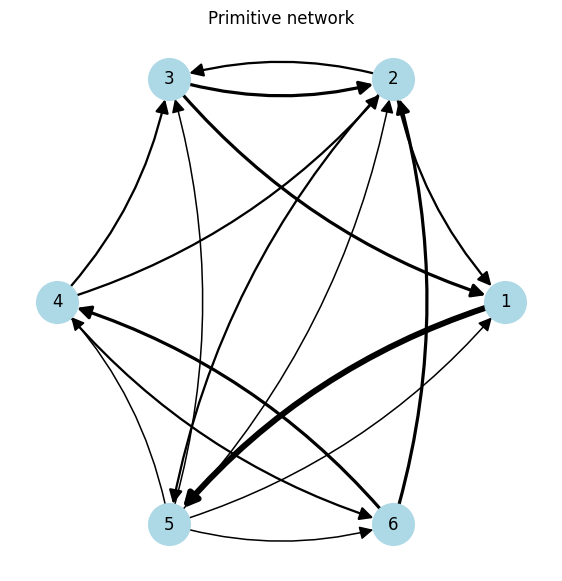

In [208]:
plot_network(P1, title="Primitive network")


In [209]:
check_primitivity(P1);


The matrix is primitive.
First strictly positive power: 3
[[0.1667 0.1778 0.2167 0.1889 0.2089 0.2556]
 [0.2667 0.1556 0.2167 0.1333 0.1867 0.2833]
 [0.1333 0.1667 0.1333 0.1889 0.1756 0.0889]
 [0.1    0.1    0.1333 0.0222 0.0867 0.1167]
 [0.2667 0.3111 0.1667 0.3889 0.2556 0.2222]
 [0.0667 0.0889 0.1333 0.0778 0.0867 0.0333]]


### 2) Finding the Stationary Distribution

We first find the ranking predicted by P1. We use `eigen_analysis`
to compute the eigenvalues and obtain the stationary distribution
from the eigenvector associated with +1.

In [210]:
eigenvalues1, pi1 = eigen_analysis(P1)


Eigenvalues:
[ 1.    +0.j      0.1089+0.3716j  0.1089-0.3716j -0.4329+0.1522j
 -0.4329-0.1522j -0.352 +0.j    ]
Absolute values of eigenvalues:
[1.     0.3872 0.3872 0.4589 0.4589 0.352 ]
Stationary distribution:
[0.1975 0.2038 0.1529 0.0955 0.2654 0.0849]


As expected, +1 is simple and every other eigenvalue has modulus
below one. The network therefore has a unique stationary distribution
that probability updates approach from any starting distribution.

Every page receives positive weight, but the ranking is not uniform.
Page 5 ranks first with probability 0.2654, while page 6 ranks last
with 0.0849. We now check how this balance emerges through repeated
updates.

### 3) Following the Probability Updates

We start by giving every page the same probability, 1/6, and apply
P1 for 20 steps. This lets us observe how the links redistribute
probability from an initially equal allocation towards the
stationary ranking.

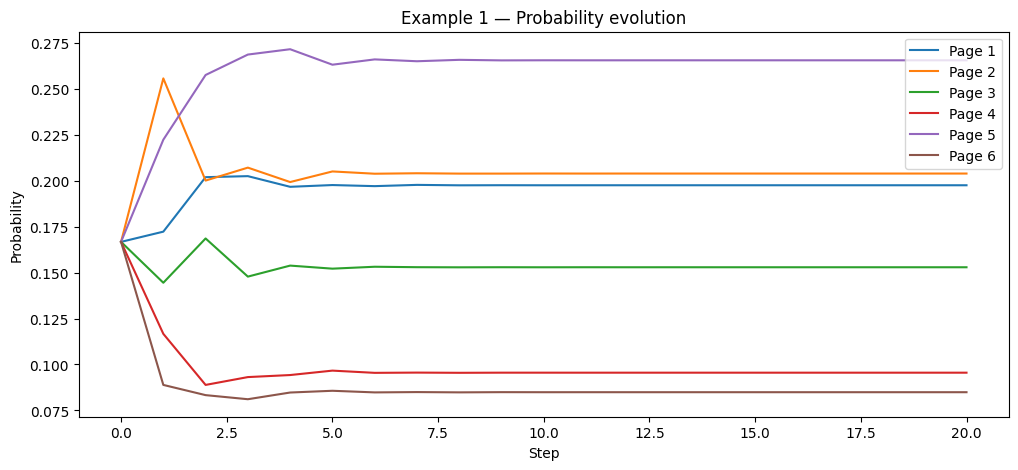

In [211]:
history1 = iterate_probabilities(
    P1, np.ones(6) / 6, 20, "Example 1 — Probability evolution"
)


The probabilities initially rise and fall as they move through
the network, then the curves flatten at different levels.
We compare the values after 20 steps with the stationary
distribution to see how close they have become.

In [212]:
comparison1 = pd.DataFrame({
    "Page": range(1, n + 1),
    "Page Probabilities after 20 steps": history1[-1],
    "Stationary distribution": pi1
})

comparison1.round(4)


,Page,Page Probabilities after 20 steps,Stationary distribution
0,1,0.1975,0.1975
1,2,0.2038,0.2038
2,3,0.1529,0.1529
3,4,0.0955,0.0955
4,5,0.2654,0.2654
5,6,0.0849,0.0849


The two columns agree to four decimal places. After 20 updates,
the initially uniform distribution is already very close to
the stationary ranking predicted by the eigenvector.

### 4) Following a Random Surfer

We now follow one simulated surfer rather than updating the whole
probability distribution. Starting from a randomly selected page,
we record 100,000 visits using P1.

The first 20 visits illustrate the path. We then use all recorded
visits to compare the observed frequencies with the stationary
probabilities.

In [213]:
frequencies1, path1 = random_surfer(P1)


,Time,Page visited
0,0,1
1,1,5
2,2,2
3,3,1
4,4,5
5,5,6
6,6,4
7,7,2
8,8,5
9,9,6


In [214]:
simulation_comparison1 = pd.DataFrame({
    "Page": range(1, P1.shape[0] + 1),
    "Simulated frequency": frequencies1,
    "Stationary probability": pi1,
})

simulation_comparison1.round(4)


,Page,Simulated frequency,Stationary probability
0,1,0.1976,0.1975
1,2,0.2033,0.2038
2,3,0.1555,0.1529
3,4,0.0947,0.0955
4,5,0.2642,0.2654
5,6,0.0846,0.0849


The simulated frequencies are close to the predicted probabilities
and reproduce the same ranking. Page 5 receives about 26.42% of
visits, compared with the predicted 26.54%.

Small differences remain because the simulation contains a finite
number of random visits. The surfer keeps moving, but the accumulated
visit shares closely reflect the balance predicted by the matrix.

### 5) Conclusion of Example 1

The three approaches tell a consistent story: the eigenvector predicts
a stationary ranking, probability updates approach it, and the simulated
surfer visits pages in approximately those proportions.

Although each outgoing link is chosen with equal probability, the pages
are not visited equally often. Their position in the network matters:
page 5 receives the largest share of visits, while page 6 receives
the smallest.

Here, the original network already has the properties we need.
Primitivity guarantees a unique, positive stationary distribution
and convergence from any initial distribution. Algebraically, +1
preserves the stationary balance, while all other eigenvalues have
modulus below one, so deviations from that balance fade over time.

No correction is needed. This gives us a reference case for the
next examples, where the network structure creates obstacles.

## Example 2 — A Network with a Dangling Page

In Example 1, the surfer always had somewhere to go. What happens
if we remove the only outgoing link from page 1 to page 5?

Page 1 can still be reached, but it now has no outgoing links:
it is a dangling page. Probability arriving there is not passed
on at the next update, so the network starts losing probability.

We keep all other links unchanged to isolate the effect of this
single modification. We first examine what breaks, then replace
the missing transition with a uniform choice among all six pages.
This allows the surfer to continue and restores stochasticity.

Finally, we compare the corrected ranking with Example 1 and
examine what changes when teleportation is available from every page.

### 1) Matrix Creation, Network and Checking Primitivity

We copy P1 and set its first column to zero, leaving all other
columns unchanged. We print the column sums to check where
probability is lost, then plot the network and call `check_primitivity` to inspect
the modified matrix.

In [215]:
P_d = P1.copy()
P_d[:, 0] = 0

print("Transition matrix:")
print(P_d)

column_sums_d = P_d.sum(axis=0).round(10)
print("Column sums:", column_sums_d)


Transition matrix:
[[0.         0.33333333 0.5        0.         0.2        0.        ]
 [0.         0.         0.5        0.33333333 0.2        0.5       ]
 [0.         0.33333333 0.         0.33333333 0.2        0.        ]
 [0.         0.         0.         0.         0.2        0.5       ]
 [0.         0.33333333 0.         0.         0.         0.        ]
 [0.         0.         0.         0.33333333 0.2        0.        ]]
Column sums: [0. 1. 1. 1. 1. 1.]


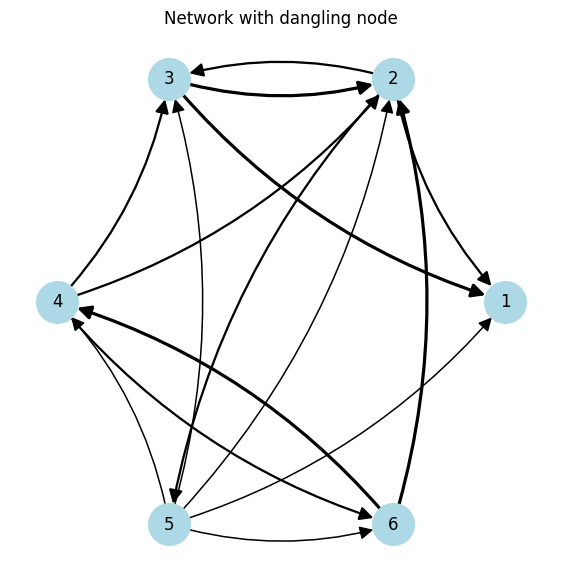

In [216]:
plot_network(P_d, title="Network with dangling node")


In [217]:
check_primitivity(P_d);


No strictly positive power found within 100 steps.
The matrix is not primitive.


The first column sums to zero, while all other columns still sum
to one. The matrix therefore no longer preserves total probability:
any probability on page 1 disappears at the next update.

The primitivity check also fails. The zero column remains zero
in every positive power of the matrix, so no power can have
all entries strictly positive.

### 2) Eigenvalues and the Missing Stationary Distribution

We use `eigen_analysis` to see whether the modified network still
admits a stationary distribution. This requires an eigenvalue
equal to +1: without it, no probability vector can remain unchanged
after an update.

In [218]:
eigenvalues_d, pi_d = eigen_analysis(P_d)


Eigenvalues:
[ 0.    +0.j      0.7164+0.j     -0.3837+0.0715j -0.3837-0.0715j
  0.0509+0.j     -0.    +0.j    ]
Absolute values of eigenvalues:
[0.     0.7164 0.3903 0.3903 0.0509 0.    ]
No eigenvalue +1: no stationary distribution.


There is no eigenvalue equal to +1, so this matrix has no stationary
distribution. All eigenvalues have modulus below one, with a maximum
of approximately 0.7164.

This tells us that repeated updates eventually send every component
to zero. In this network, the leak ultimately drains all probability,
not just the probability initially assigned to page 1.

### 3) Following the Probability Updates

We start with probability 1/6 on each page and apply P_d for 20 steps.
The plot shows how the missing outgoing link affects probability
throughout the network.

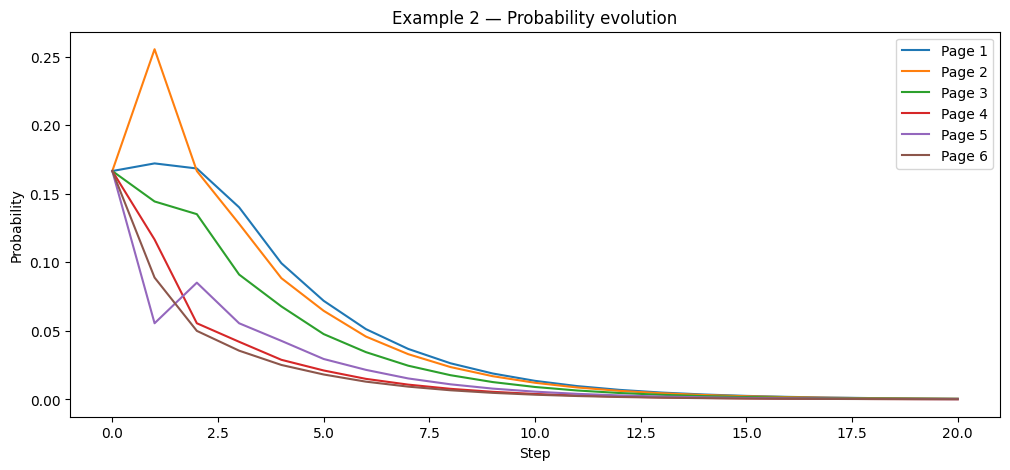

In [219]:
history_d = iterate_probabilities(
    P_d, np.ones(6) / 6, 20, "Example 2 — Probability evolution"
)


The curves approach zero instead of settling at a stationary ranking.
At each update, any probability on page 1 disappears, while probability
on the other pages continues moving through the remaining links.

These values therefore describe the probability mass still present
on each page. Their total is no longer one: the network gradually
loses all its mass, as predicted by the eigenvalues.

In [220]:
comparison2 = pd.DataFrame({
    "Page": range(1, P_d.shape[0] + 1),
    "Page Probabilities after 20 steps": history_d[-1],
    "Stationary distribution": pi_d
})

comparison2.round(4)

,Page,Page Probabilities after 20 steps,Stationary distribution
0,1,0.0005,None
1,2,0.0004,None
2,3,0.0003,None
3,4,0.0001,None
4,5,0.0002,None
5,6,0.0001,None


The two columns of the comparison table show how the probabilities of each page fall toward zero, confirming that the network has no stationary distribution.

### 4) Can We Simulate the Random Surfer?

We now try the same simulation used in Example 1. The function first
checks whether each column provides valid probabilities for choosing
the next page.

In [221]:
random_surfer(P_d);


The simulation cannot start: P must be column-stochastic.
Entries must be nonnegative and each column must sum to one.


The simulation cannot start because page 1's column sums to zero.
The function detects this before generating any visits.

The missing link leaves a simple question unanswered: once the surfer
reaches page 1, where should it go next? Probability iteration reveals
this missing rule as lost mass, while the simulation refuses to proceed
without valid transitions.

We now correct the dangling column so that the surfer always has
a next move.

### 5) Correcting the Dangling Page

We give the surfer a way to continue: whenever it reaches page 1,
it chooses uniformly among all six pages, including page 1 itself.

The function `correct_dangling` implements this rule by replacing
the zero column with probabilities of 1/6. We then check whether
the corrected matrix S_d is primitive.

In [222]:
S_d = correct_dangling(P_d)


Matrix after dangling-node correction:
[[0.1667 0.3333 0.5    0.     0.2    0.    ]
 [0.1667 0.     0.5    0.3333 0.2    0.5   ]
 [0.1667 0.3333 0.     0.3333 0.2    0.    ]
 [0.1667 0.     0.     0.     0.2    0.5   ]
 [0.1667 0.3333 0.     0.     0.     0.    ]
 [0.1667 0.     0.     0.3333 0.2    0.    ]]
Column sums:
[1. 1. 1. 1. 1. 1.]


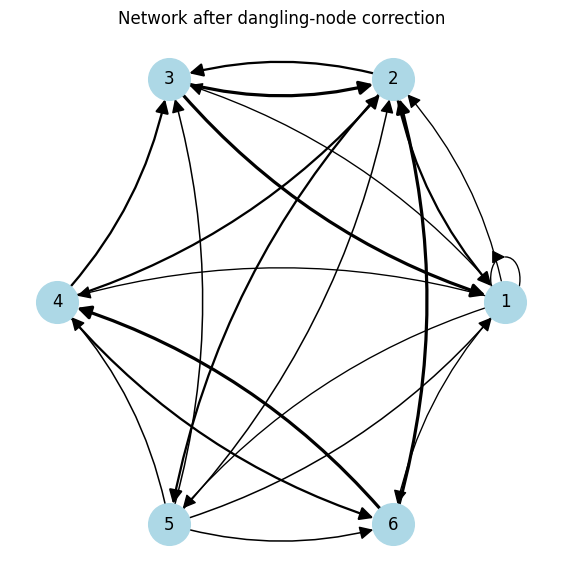

In [223]:
plot_network(S_d, title="Network after dangling-node correction")


In [224]:
check_primitivity(S_d);


The matrix is primitive.
First strictly positive power: 3
[[0.2306 0.2167 0.2444 0.2352 0.2367 0.2833]
 [0.2426 0.2222 0.2861 0.1796 0.2311 0.3111]
 [0.1926 0.1963 0.1472 0.2352 0.1978 0.1167]
 [0.1083 0.1204 0.1333 0.0685 0.1033 0.1444]
 [0.1278 0.1444 0.0694 0.1574 0.1333 0.0833]
 [0.0981 0.1    0.1194 0.1241 0.0978 0.0611]]


Every column now sums to one: probability reaching page 1 is
redistributed instead of disappearing.

The first strictly positive power is S_d³. In this network,
the dangling correction therefore restores not only stochasticity
but also primitivity. A unique, positive stationary distribution
exists, and probability updates converge to it from any initial
distribution.

In [225]:
eigenvalues_Sd, pi_Sd = eigen_analysis(S_d)

Eigenvalues:
[ 1.    +0.j      0.0493+0.2776j  0.0493-0.2776j -0.1477+0.j
 -0.3922+0.0631j -0.3922-0.0631j]
Absolute values of eigenvalues:
[1.     0.2819 0.2819 0.1477 0.3972 0.3972]
Stationary distribution:
[0.2363 0.244  0.183  0.1144 0.1207 0.1017]


The eigenvalues confirm the expected behaviour: +1 is simple,
and all other eigenvalues have modulus below one.

All six pages now have positive stationary probabilities.
Page 2 ranks first with 0.2440, followed by page 1 with 0.2363.
The corrected network can sustain a stable ranking again.

The correction does not recreate the original link from page 1
to page 5: it introduces a uniform choice instead. We should therefore
expect a different ranking from Example 1. No further correction
is needed for convergence here, although dangling correction alone
does not guarantee primitivity in every network.

### 6) Following the probability updates after correction

Starting from the same uniform distribution, we compare 20 updates
before and after correcting the dangling page.

Colours identify pages. Dashed lines show the original matrix P_d;
solid lines show the corrected matrix S_d.

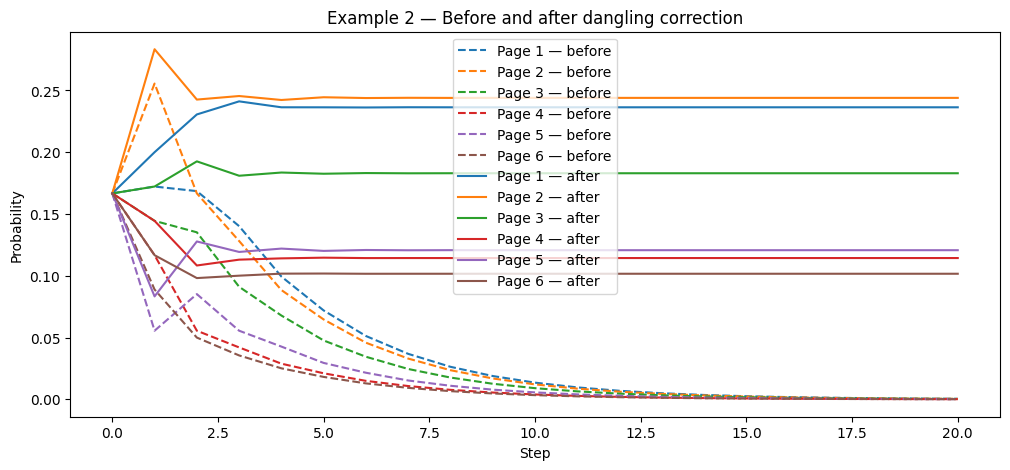

In [226]:
history_d = iterate_probabilities(
    P_d, np.ones(6) / 6, 20,
    "Example 2 — Before and after dangling correction",
    show=False, style="--", label=" — before"
)

history_Sd = iterate_probabilities(
    S_d, np.ones(6) / 6, 20,
    "Example 2 — Before and after dangling correction",
    new_figure=False, label=" — after"
)

Without correction, the dashed curves approach zero as probability
leaks out through page 1. After correction, the solid curves settle
at positive stationary values: probability is redistributed instead
of disappearing.

The contrast shows what the correction achieves: it keeps probability
inside the network and, in this example, allows a stable ranking
to emerge.

In [227]:
comparison_Sd = pd.DataFrame({
    "Page": range(1, 7),
    "Page Probabilities after 20 steps": history_Sd[-1],
    "Stationary distribution of S_d": pi_Sd,
    "Stationary distribution of Example 1": pi1
})

comparison_Sd.round(4)

,Page,Page Probabilities after 20 steps,Stationary distribution of S_d,Stationary distribution of Example 1
0,1,0.2363,0.2363,0.1975
1,2,0.2440,0.2440,0.2038
2,3,0.1830,0.1830,0.1529
3,4,0.1144,0.1144,0.0955
4,5,0.1207,0.1207,0.2654
5,6,0.1017,0.1017,0.0849


After 20 updates, the probabilities agree with the stationary
distribution of S_d to four decimal places. The correction has
restored convergence, but the resulting ranking differs from
Example 1.

The largest change concerns page 5, whose stationary probability
falls from 0.2654 to 0.1207. Previously, page 1 sent all its probability
to page 5; now it distributes that probability equally among six
destinations. Page 5 loses this exclusive source of incoming
probability, and page 2 takes first place.

Correcting the dangling page therefore restores a working navigation
rule without recreating the original network.

### 7) Random Surfing and Visit Frequencies

With the dangling page corrected, the surfer can now continue
from every page. We simulate 100,000 visits using S_d, starting
from a randomly selected page.

At page 1, the surfer chooses uniformly among all six pages.
Elsewhere, it follows the original links. We display the first
20 visits and compare the frequencies from the full simulation
with the stationary distribution.

In [228]:
frequencies_Sd, path_Sd = random_surfer(S_d)


,Time,Page visited
0,0,1
1,1,1
2,2,2
3,3,1
4,4,2
5,5,5
6,6,6
7,7,2
8,8,5
9,9,6


Page 1 is no longer a dead end. Whenever the surfer reaches it,
the uniform jump supplies a next destination, possibly page 1
itself. This rule allows the simulation to continue without
losing visits.

In [229]:
simulation_comparison_Sd = pd.DataFrame({
    "Page": range(1, S_d.shape[0] + 1),
    "Simulated frequency": frequencies_Sd,
    "Stationary probability": pi_Sd
})

simulation_comparison_Sd.round(4)

,Page,Simulated frequency,Stationary probability
0,1,0.2366,0.2363
1,2,0.2439,0.2440
2,3,0.1844,0.1830
3,4,0.1154,0.1144
4,5,0.1184,0.1207
5,6,0.1013,0.1017


The simulated frequencies approximate the stationary probabilities,
with small differences due to the finite number of random visits.

The correction therefore connects the three perspectives again:
the eigenvector predicts a stationary ranking, probability updates
approach it, and simulated visits reproduce it approximately.

### 8) Conclusion of Example 2

Removing one link left page 1 without a next destination.
In this network, probability updates gradually lost all their mass,
and the simulation could not start because the transition matrix
was no longer stochastic. A dangling page does not retain probability:
its zero column lets probability disappear at the next update.

Replacing that column with uniform probabilities supplied the missing
navigation rule. In this example, the corrected matrix is also
primitive: probability updates approach a unique, positive stationary
distribution, and simulated visit frequencies approximate the same
ranking. No further correction is needed.

However, fixing the problem does not restore the original network.
Page 1 now distributes its probability among all six pages instead
of sending everything to page 5. Consequently, page 5 falls from
first to fourth place.

The lesson is that specifying what happens at a dangling page is
essential for the model to work, and the rule we choose also affects
the resulting ranking.

## Example 3.1 — A Network with a Closed Group

In Example 2, probability disappeared because a page had no outgoing
links. Here, every page has a next destination and probability is
preserved—but the surfer can become trapped.

Pages 4–6 form a closed group: the surfer can enter from pages 1–3,
but cannot return to them. We construct the group so that probabilities
can settle without persistent oscillations.

Can a stable ranking therefore leave some pages with zero weight?
We examine the stationary distribution, probability updates, and
simulated visits, then introduce teleportation to give the surfer
a way out of the group.

### 1) Matrix Creation, Network and Checking Primitivity

We build a six-page network with a prescribed closed group.
Each of pages 1–3 receives two distinct outgoing links, at least
one of which leads to pages 4–6. Each link has probability 0.5.

As the graph will show, within the group, we create the cycle 4 → 5 → 6 → 4.
We then randomly select one page and let it link to both other
pages in the group, with equal probabilities.

This extra connection creates a shorter route back: a return can
take two steps as well as three. The group therefore has no fixed
return rhythm greater than one and is aperiodic.

Self-links are excluded, and the seed is fixed for reproducibility.

We then call `check_primitivity` on the resulting matrix P2.

In [230]:
rng = np.random.default_rng(123)
n = 6
P2 = np.zeros((n, n))

for j in range(3):
    first = rng.choice(range(3, n))

    candidates = []

    for i in range(n):
        if i != j and i != first:
            candidates.append(i)

    second = rng.choice(candidates)

    P2[first, j] = 0.5
    P2[second, j] = 0.5

for j in range(3, n):
    destination = j + 1

    if destination == n:
        destination = 3

    P2[destination, j] = 1

source = rng.choice(range(3, n))

for i in range(3, n):
    if i != source:
        P2[i, source] = 0.5

print("Transition matrix:")
print(P2)


Transition matrix:
[[0.  0.5 0.5 0.  0.  0. ]
 [0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0. ]
 [0.5 0.  0.  0.  0.  1. ]
 [0.5 0.5 0.  0.5 0.  0. ]
 [0.  0.  0.5 0.5 1.  0. ]]


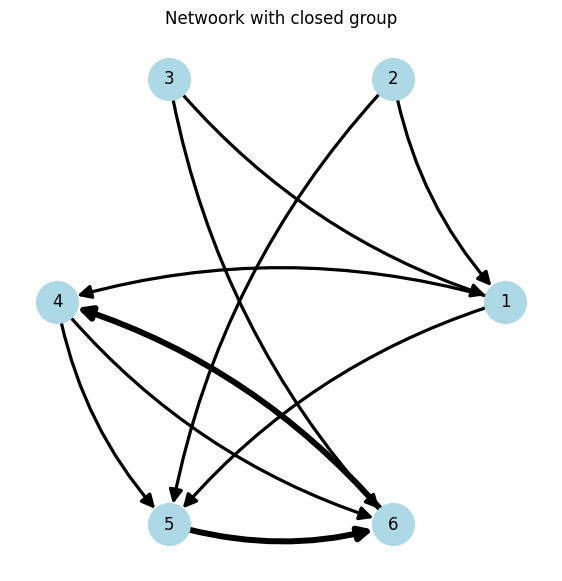

In [231]:
plot_network(P2, title="Netwoork with closed group")


In [232]:
check_primitivity(P2);


No strictly positive power found within 100 steps.
The matrix is not primitive.


The matrix is not primitive. Starting from pages 4–6, the surfer
cannot reach pages 1–3, however many steps are allowed. These
transition probabilities remain zero in every power of P2.

Unlike the dangling example, every column sums to one: probability
is preserved. The obstacle is that it can enter a part of the
network from which it cannot escape.

### 2) Eigenvalues and Stationary Distribution

We use `eigen_analysis` to find the stationary ranking and check
whether probability updates can converge even though P2 is
not primitive.

In [233]:
eigenvalues2, pi2 = eigen_analysis(P2)


Eigenvalues:
[ 1. +0.j  -0.5+0.5j -0.5-0.5j  0. +0.j   0. +0.j   0. +0.j ]
Absolute values of eigenvalues:
[1.     0.7071 0.7071 0.     0.     0.    ]
Stationary distribution:
[-0.  -0.  -0.   0.4  0.2  0.4]


The stationary distribution gives positive weight only to pages 4–6.
Pages 1–3 receive zero: probability can flow from them into the
closed group, but cannot return.

Nevertheless, +1 is simple and all other eigenvalues have modulus
below one, so probability updates converge to this unique distribution.
The single closed group is aperiodic: probabilities can settle
within it even though the whole network is not irreducible.

The problem here is therefore a ranking that excludes some pages,
rather than a failure to converge.

### 3) Following the Probability Updates

We start with probability 1/6 on each page and apply P2 for 20 steps.
This shows how an initially equal allocation becomes concentrated
inside the closed group.

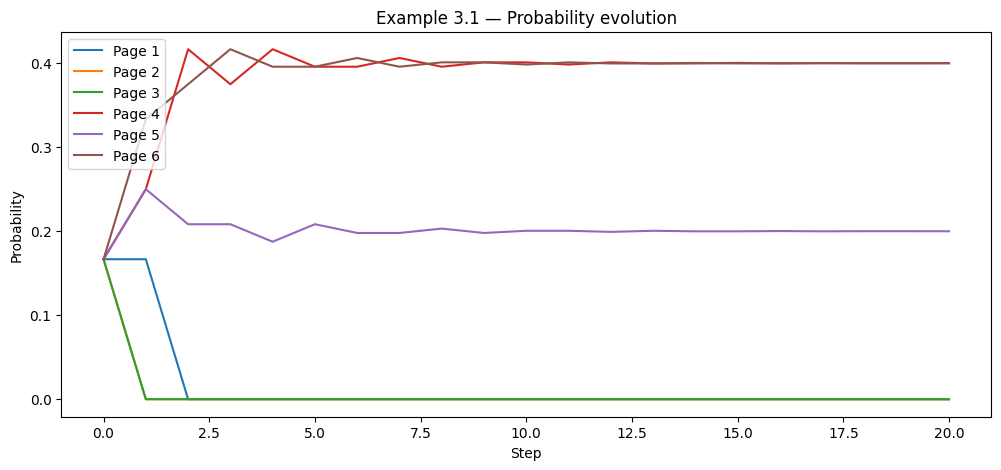

In [234]:
history2 = iterate_probabilities(
    P2, np.ones(6) / 6, 20, "Example 3.1 — Probability evolution"
)


The probabilities of pages 1–3 fall to zero, while those of pages
4–6 settle at positive levels. Unlike the dangling example,
no probability disappears: it all moves into the closed group.

We compare the values after 20 updates with the stationary
distribution predicted by the eigenvector.

In [235]:
comparison2 = pd.DataFrame({
    "Page": range(1, P2.shape[0] + 1),
    "Page Probabilities after 20 steps": history2[-1],
    "Stationary distribution": pi2
})
comparison2.round(4)

,Page,Page Probabilities after 20 steps,Stationary distribution
0,1,0.0000,-0.0
1,2,0.0000,-0.0
2,3,0.0000,-0.0
3,4,0.4001,0.4
4,5,0.2000,0.2
5,6,0.4000,0.4


After 20 updates, the values are close to the stationary distribution.
The network reaches a stable balance, but that balance is supported
entirely on pages 4–6.

### 4) Random Surfing and Visit Frequencies

We simulate 100,000 visits from a randomly selected starting page.
The first 20 visits illustrate how the surfer moves; the frequencies
from the full simulation show where it spends its time.

Once the surfer enters pages 4–6, all subsequent visits remain
inside that group.

In [236]:
frequencies2, path2 = random_surfer(P2)


,Time,Page visited
0,0,1
1,1,4
2,2,5
3,3,6
4,4,4
5,5,6
6,6,4
7,7,5
8,8,6
9,9,4


In [237]:
simulation_comparison2 = pd.DataFrame({
    "Page": range(1, P2.shape[0] + 1),
    "Simulated frequency": frequencies2,
    "Stationary probability": pi2,
})

simulation_comparison2.round(4)


,Page,Simulated frequency,Stationary probability
0,1,0.0000,-0.0
1,2,0.0000,-0.0
2,3,0.0000,-0.0
3,4,0.3998,0.4
4,5,0.2004,0.2
5,6,0.3998,0.4


The visit frequencies approximate the stationary ranking within
pages 4–6. Any visits to pages 1–3 occur only before entering the
group, so their share becomes negligible as more visits accumulate.

The surfer keeps moving, but explores only part of the network.
We next introduce teleportation to make it possible to leave
the group and revisit the other pages.

### 5) Applying Teleportation

We give the surfer a way out of the closed group. With probability
0.85, it follows an original link; with probability 0.15, it chooses
uniformly among all six pages.

We construct G2, check primitivity, and compute its stationary
distribution.

In [238]:
G2 = google_matrix(P2)


Google matrix:
[[0.025 0.45  0.45  0.025 0.025 0.025]
 [0.025 0.025 0.025 0.025 0.025 0.025]
 [0.025 0.025 0.025 0.025 0.025 0.025]
 [0.45  0.025 0.025 0.025 0.025 0.875]
 [0.45  0.45  0.025 0.45  0.025 0.025]
 [0.025 0.025 0.45  0.45  0.875 0.025]]


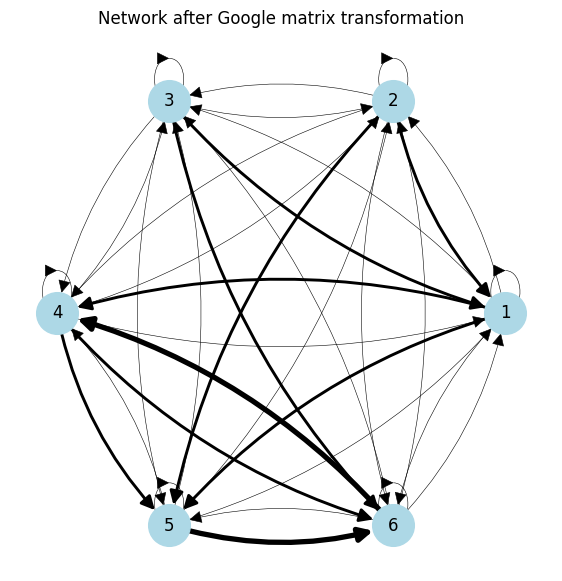

In [239]:
plot_network(G2, title="Network after Google matrix transformation")


In [240]:
check_primitivity(G2);


The matrix is primitive.
First strictly positive power: 1
[[0.025 0.45  0.45  0.025 0.025 0.025]
 [0.025 0.025 0.025 0.025 0.025 0.025]
 [0.025 0.025 0.025 0.025 0.025 0.025]
 [0.45  0.025 0.025 0.025 0.025 0.875]
 [0.45  0.45  0.025 0.45  0.025 0.025]
 [0.025 0.025 0.45  0.45  0.875 0.025]]


Teleportation gives the surfer a possible route from any page
to any other page, including destinations outside the closed group.

Every entry of G2 is positive, so the first power already passes
the primitivity check. We now examine the eigenvalues and the
stationary distribution to see how this changes the ranking.

In [241]:
eigenvalues_G2, pi_G2 = eigen_analysis(G2)


Eigenvalues:
[ 1.   +0.j    -0.425+0.425j -0.425-0.425j -0.   +0.j     0.   +0.j
  0.   +0.j   ]
Absolute values of eigenvalues:
[1.    0.601 0.601 0.    0.    0.   ]
Stationary distribution:
[0.0462 0.025  0.025  0.3463 0.2025 0.3549]


The eigenvalue +1 is simple and all other eigenvalues have modulus
below one. Probability updates therefore converge to a unique
stationary distribution.

This also happened before teleportation. The key change is that
the stationary vector now has positive entries for all six pages:
pages 1–3 are no longer excluded from the final ranking.

Pages 2 and 3 each receive probability 0.025. Since no original
links lead to them, their stationary probability comes entirely
from uniform teleportation: 0.15 divided among six pages.

### 6) Following the Probability Updates with Teleportation

Starting from the same uniform distribution, we compare 20 updates under P2 (dashed lines) and G2 (solid lines). Colours identify the pages.


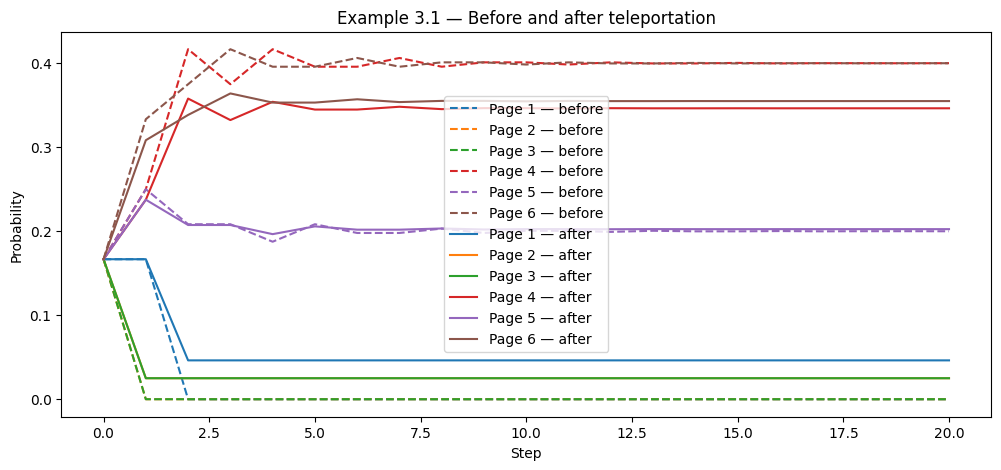

In [242]:
history2 = iterate_probabilities(
    P2, np.ones(6) / 6, 20,
    "Example 3.1 — Before and after teleportation",
    show=False, style="--", label=" — before"
)

history_G2 = iterate_probabilities(
    G2, np.ones(6) / 6, 20,
    "Example 3.1 — Before and after teleportation",
    new_figure=False, label=" — after"
)


Without teleportation, pages 1–3 lose all their probability to
the closed group. With teleportation, probability can flow back
to them, and their curves settle at positive values.

The table below compares the probabilities after 20 updates
with the new stationary distribution and the original ranking.

In [243]:
comparison_G2 = pd.DataFrame({
    "Page": range(1, P2.shape[0] + 1),
    "Page Probabilities after 20 steps": history_G2[-1],
    "Stationary distribution with teleportation": pi_G2,
    "Stationary distribution before teleportation": pi2
})
comparison_G2.round(4)

,Page,Page Probabilities after 20 steps,Stationary distribution with teleportation,Stationary distribution before teleportation
0,1,0.0462,0.0462,-0.0
1,2,0.0250,0.0250,-0.0
2,3,0.0250,0.0250,-0.0
3,4,0.3463,0.3463,0.4
4,5,0.2025,0.2025,0.2
5,6,0.3549,0.3549,0.4


After 20 updates, the probabilities are close to the stationary
distribution of G2. Unlike the original ranking, it assigns positive
weight to every page.

Pages 4–6 still benefit from their internal links, but they no longer
retain all the probability. Teleportation allows the rest of the
network to remain part of the stationary ranking.

### 7) Random Surfing with Teleportation

We simulate 100,000 visits using G2. The surfer can now leave
pages 4–6 and revisit the rest of the network.

We display the first 20 visits, then compare the frequencies
from the full simulation with the stationary distribution of G2.

In [244]:
frequencies_G2, path_G2 = random_surfer(G2)


,Time,Page visited
0,0,1
1,1,3
2,2,1
3,3,4
4,4,5
5,5,6
6,6,4
7,7,5
8,8,6
9,9,4


The surfer starts on page 1 and moves to page 3 at step 1.
This move must come from teleportation: page 1 has no original
link to page 3.

It then returns to page 1 and enters pages 4–6 at step 3.
Although the remaining displayed visits stay within this group,
there is now a possibility of leaving at every step. A short
path need not show an exit for that escape route to exist.

In [245]:
simulation_comparison_G2 = pd.DataFrame({
    "Page": range(1, G2.shape[0] + 1),
    "Simulated frequency": frequencies_G2,
    "Stationary probability": pi_G2,
})

simulation_comparison_G2.round(4)


,Page,Simulated frequency,Stationary probability
0,1,0.0458,0.0462
1,2,0.0249,0.0250
2,3,0.0252,0.0250
3,4,0.3476,0.3463
4,5,0.2024,0.2025
5,6,0.3542,0.3549


The simulated frequencies are close to the stationary probabilities,
and all six pages receive visits. Pages 1–3 now remain part of
the surfer's activity instead of appearing only before entry
into the closed group.

The frequencies are still unequal: teleportation allows movement
throughout the network, while the original links continue to
shape the ranking.

### 8) Conclusion of Example 3.1

A ranking can settle and still leave some pages behind.
Under P2, probability accumulates in pages 4–6 because the original
links provide no way out. The stationary distribution exists
and is unique, but assigns zero probability to pages 1–3.

The eigenvalues explain why convergence still occurs: +1 is simple
and every other eigenvalue has modulus below one. What is missing
is positive stationary weight for every page.

Teleportation resolves this by allowing the surfer to leave
the group and revisit the other pages. The resulting matrix G2
is primitive, and its stationary distribution is positive
throughout the network.

Here, the correction does not create convergence where it was
absent. It makes the stable ranking include every page, while
preserving the influence of the original links.

## Example 3.2 — A Network with Two Closed Groups

Pages 1 and 2 link to each other, but each also provides an entrance
to a different closed group: page 1 links to page 3, while page 2
links to page 6.

Pages 3–5 form one closed group, and pages 6–8 form another.
Within each group, every page links to the other two with equal
probabilities. Both groups are irreducible and aperiodic.

The surfer can move between pages 1 and 2 before entering either
group. Once inside a group, it cannot leave.

We examine why the stationary distribution is no longer unique,
how probability updates depend on the initial distribution, and
how teleportation changes the result.

### 1) Matrix Creation and Network

We construct an eight-page network. Each page has two outgoing
links, each with probability 0.5. Self-links are excluded, and
every column sums to one.

Transition matrix:
[[0.  0.5 0.  0.  0.  0.  0.  0. ]
 [0.5 0.  0.  0.  0.  0.  0.  0. ]
 [0.5 0.  0.  0.5 0.5 0.  0.  0. ]
 [0.  0.  0.5 0.  0.5 0.  0.  0. ]
 [0.  0.  0.5 0.5 0.  0.  0.  0. ]
 [0.  0.5 0.  0.  0.  0.  0.5 0.5]
 [0.  0.  0.  0.  0.  0.5 0.  0.5]
 [0.  0.  0.  0.  0.  0.5 0.5 0. ]]


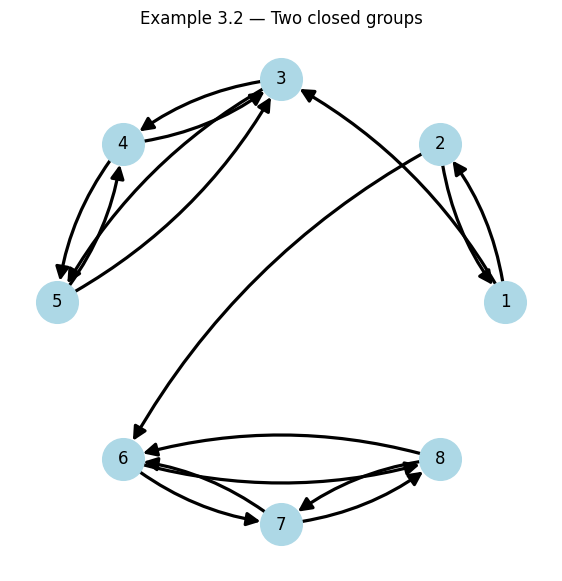

In [246]:
n = 8
P_double = np.zeros((n, n))

# Page 1 links to pages 2 and 3
P_double[1, 0] = 0.5
P_double[2, 0] = 0.5

# Page 2 links to pages 1 and 6
P_double[0, 1] = 0.5
P_double[5, 1] = 0.5

# First closed group: pages 3, 4 and 5
for j in range(2, 5):
    for i in range(2, 5):
        if i != j:
            P_double[i, j] = 0.5

# Second closed group: pages 6, 7 and 8
for j in range(5, 8):
    for i in range(5, 8):
        if i != j:
            P_double[i, j] = 0.5

print("Transition matrix:")
print(P_double)

plot_network(
    P_double,
    title="Example 3.2 — Two closed groups"
)

### 2) Checking Primitivity

We check whether a power of P_double has all entries strictly positive.
Once the surfer enters either closed group, it cannot reach the other
group or return to pages 1 and 2. These transitions remain impossible
regardless of the number of updates.

In [247]:
check_primitivity(P_double);

No strictly positive power found within 100 steps.
The matrix is not primitive.


The matrix is not primitive. Each closed group is internally connected
and aperiodic, but the whole network is reducible.

Every column still sums to one: probability is preserved, even though
it cannot move between the two closed groups.

### 3) Eigenvalues and Stationary Distributions

We compute the eigenvalues and examine the eigenvalue +1.
In Example 3, a single closed group gave a unique stationary
distribution. Here, each closed group supports its own stationary
distribution, so uniqueness is no longer guaranteed.

In [248]:
eigenvalues_double, pi_double = eigen_analysis(P_double)

Eigenvalues:
[ 1. +0.j  0.5+0.j  1. +0.j -0.5+0.j -0.5-0.j -0.5+0.j -0.5+0.j -0.5+0.j]
Absolute values of eigenvalues:
[1.  0.5 1.  0.5 0.5 0.5 0.5 0.5]
No unique stationary distribution.
Stationary distribution 1 :
[0.     0.     0.3333 0.3333 0.3333 0.     0.     0.    ]
Stationary distribution 2 :
[0.     0.     0.     0.     0.     0.3333 0.3333 0.3333]
Every convex combination of these vectors is also a stationary distribution.


The eigenvalue +1 has multiplicity two, so the stationary distribution
is not unique. The function returns two stationary vectors: one supported
on pages 3–5 and the other on pages 6–8.

Any convex combination of these vectors is also stationary.
Probability updates converge, but the weight assigned to each group
depends on the initial distribution.

### 4) Following the Probability Updates

We compare three initial distributions: all probability on page 1,
all probability on page 2, and equal probability on all eight pages.

These updates describe probability distributions across all possible
paths, not individual trajectories. Both starting pages can lead to
either closed group, but with different probabilities.

We follow 30 updates for each initial distribution.

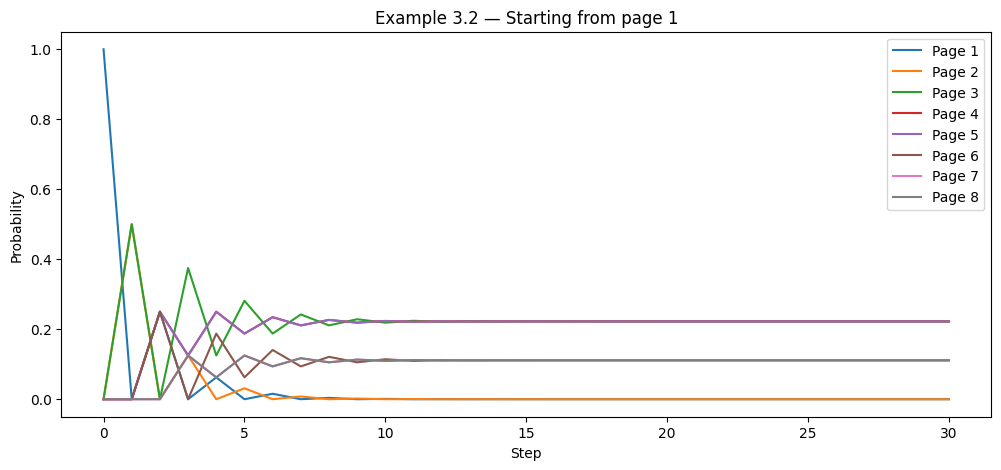

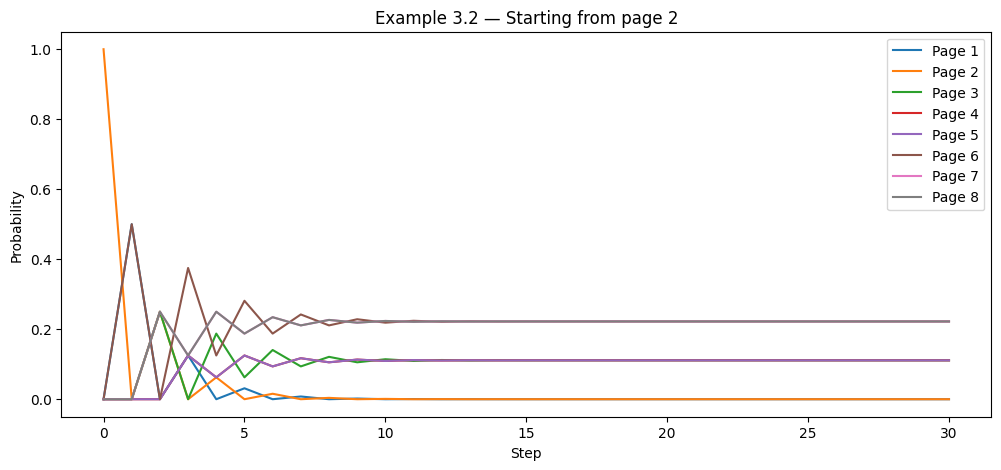

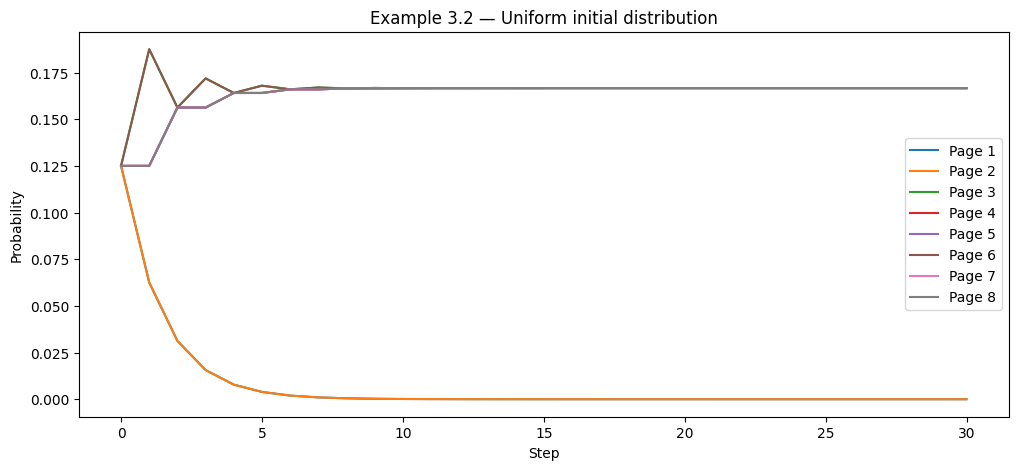

In [249]:
x0_page1 = np.zeros(8)
x0_page1[0] = 1

x0_page2 = np.zeros(8)
x0_page2[1] = 1

x0_uniform = np.ones(8) / 8

history_double1 = iterate_probabilities(
    P_double, x0_page1, 30,
    "Example 3.2 — Starting from page 1"
)

history_double2 = iterate_probabilities(
    P_double, x0_page2, 30,
    "Example 3.2 — Starting from page 2"
)

history_double_uniform = iterate_probabilities(
    P_double, x0_uniform, 30,
    "Example 3.2 — Uniform initial distribution"
)

Probability on pages 1 and 2 tends to zero, while probability within
each closed group becomes uniform. The total assigned to each group
depends on the initial distribution.

We compare the final values for the three starting distributions.

In [250]:
comparison_double = pd.DataFrame({
    "Page": range(1, 9),
    "Start on page 1": history_double1[-1],
    "Start on page 2": history_double2[-1],
    "Uniform start": history_double_uniform[-1]
})

comparison_double.round(4)

,Page,Start on page 1,Start on page 2,Uniform start
0,1,0.0000,0.0000,0.0000
1,2,0.0000,0.0000,0.0000
2,3,0.2222,0.1111,0.1667
3,4,0.2222,0.1111,0.1667
4,5,0.2222,0.1111,0.1667
5,6,0.1111,0.2222,0.1667
6,7,0.1111,0.2222,0.1667
7,8,0.1111,0.2222,0.1667


Starting on page 1 gives limiting total probabilities of 2/3 on
pages 3–5 and 1/3 on pages 6–8. Starting on page 2 reverses these weights.

With a uniform start, symmetry gives half the probability to each
group, so each of pages 3–8 approaches 1/6.

All three distributions converge, but to different stationary
distributions. These group weights describe probabilities across
possible paths: a single surfer eventually remains in just one group.

### 5) Random Surfing and Visit Frequencies

We simulate four surfers, each starting randomly on page 1 or page 2
with equal probability. We display their first 20 visits side by side.

Each surfer eventually enters one closed group and remains there.
Different simulations may enter different groups, but this is not
guaranteed.

In [251]:
rng_start = np.random.default_rng(123)
seeds_double = [123, 456, 789, 1011]

paths_double = {}
frequencies_double_runs = {}

for run, seed in enumerate(seeds_double, start=1):
    start_page = rng_start.choice([1, 2])

    frequencies, path = random_surfer(
        P_double,
        n_visits=100000,
        seed=seed,
        show=False,
        start_page=start_page
    )

    name = f"Simulation {run}"
    paths_double[name] = path
    frequencies_double_runs[name] = frequencies

paths_table_double = pd.DataFrame(paths_double)
paths_table_double.index.name = "Time"

display(paths_table_double)

,Simulation 1,Simulation 2,Simulation 3,Simulation 4
Time,,,,
0,1,2,2,1
1,3,1,1,2
2,4,2,2,6
3,3,1,6,7
4,4,3,7,6
5,3,5,6,7
6,5,3,8,6
7,4,4,6,7
8,3,5,7,8


Simulations 1 and 2 enter pages 3–5, while simulations 3 and 4 enter
pages 6–8. Once inside, each surfer remains in that group.

The same starting page can lead to different outcomes: simulations
1 and 4 both start on page 1, but enter different groups. The same
happens for simulations 2 and 3, starting on page 2.

We now compare the full-simulation visit frequencies with the two
stationary distributions.

In [252]:
simulation_double = pd.DataFrame({
    "Page": range(1, 9),
    **frequencies_double_runs,
    "Stationary distribution 1": pi_double[:, 0],
    "Stationary distribution 2": pi_double[:, 1]
})

display(simulation_double.round(4))

,Page,Simulation 1,Simulation 2,Simulation 3,Simulation 4,Stationary distribution 1,Stationary distribution 2
0,1,0.0000,0.0000,0.000,0.0000,0.0000,0.0000
1,2,0.0000,0.0000,0.000,0.0000,0.0000,0.0000
2,3,0.3317,0.3345,0.000,0.0000,0.3333,0.0000
3,4,0.3358,0.3336,0.000,0.0000,0.3333,0.0000
4,5,0.3325,0.3318,0.000,0.0000,0.3333,0.0000
5,6,0.0000,0.0000,0.334,0.3339,0.0000,0.3333
6,7,0.0000,0.0000,0.333,0.3338,0.0000,0.3333
7,8,0.0000,0.0000,0.333,0.3323,0.0000,0.3333


Simulations 1 and 2 approximate the first stationary distribution,
while simulations 3 and 4 approximate the second. Within the group
entered, each page receives approximately one third of the visits.

Pages 1 and 2 were visited initially, but their frequencies are so
small that they round to zero. Small deviations from 1/3 reflect
the finite simulation length.

Each trajectory approaches one group-specific distribution.
The mixtures obtained from probability updates instead describe
the probabilities of the different possible outcomes.

### 6) Applying Teleportation

With probability 0.85, the surfer follows the original transition
probabilities. With probability 0.15, it chooses uniformly among all
eight pages, including its current page.

This allows the surfer to leave either closed group and return to
pages 1 and 2. We construct G_double and check its primitivity.

In [253]:
G_double = google_matrix(P_double)

Google matrix:
[[0.0188 0.4438 0.0188 0.0188 0.0188 0.0188 0.0188 0.0188]
 [0.4438 0.0188 0.0188 0.0188 0.0188 0.0188 0.0188 0.0188]
 [0.4438 0.0188 0.0188 0.4438 0.4438 0.0188 0.0188 0.0188]
 [0.0188 0.0188 0.4438 0.0188 0.4438 0.0188 0.0188 0.0188]
 [0.0188 0.0188 0.4438 0.4438 0.0188 0.0188 0.0188 0.0188]
 [0.0188 0.4438 0.0188 0.0188 0.0188 0.0188 0.4438 0.4438]
 [0.0188 0.0188 0.0188 0.0188 0.0188 0.4438 0.0188 0.4438]
 [0.0188 0.0188 0.0188 0.0188 0.0188 0.4438 0.4438 0.0188]]


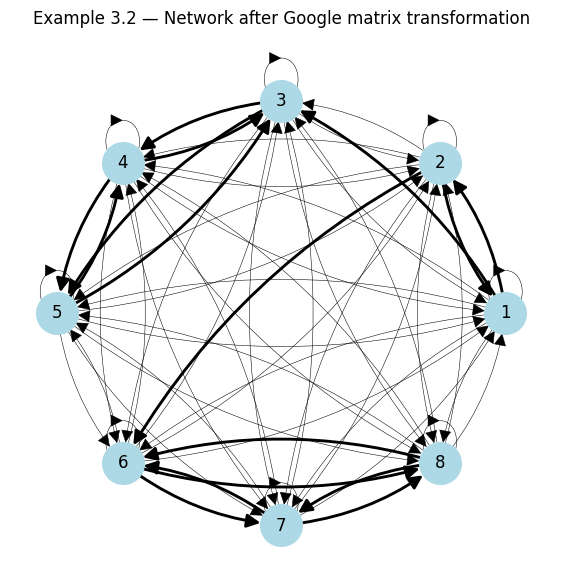

In [254]:
plot_network(
    G_double,
    title="Example 3.2 — Network after Google matrix transformation"
)

In [255]:
check_primitivity(G_double);

The matrix is primitive.
First strictly positive power: 1
[[0.0188 0.4438 0.0188 0.0188 0.0188 0.0188 0.0188 0.0188]
 [0.4438 0.0188 0.0188 0.0188 0.0188 0.0188 0.0188 0.0188]
 [0.4438 0.0188 0.0188 0.4438 0.4438 0.0188 0.0188 0.0188]
 [0.0188 0.0188 0.4438 0.0188 0.4438 0.0188 0.0188 0.0188]
 [0.0188 0.0188 0.4438 0.4438 0.0188 0.0188 0.0188 0.0188]
 [0.0188 0.4438 0.0188 0.0188 0.0188 0.0188 0.4438 0.4438]
 [0.0188 0.0188 0.0188 0.0188 0.0188 0.4438 0.0188 0.4438]
 [0.0188 0.0188 0.0188 0.0188 0.0188 0.4438 0.4438 0.0188]]


Every entry of G_double is positive, so the primitivity check succeeds
at the first power. The surfer can now reach any page directly and
can also remain where it is.

We next examine how these new possibilities change the eigenvalues
and the stationary distribution.

In [256]:
eigenvalues_G_double, pi_G_double = eigen_analysis(G_double)

Eigenvalues:
[-0.425+0.j -0.425-0.j  0.425+0.j  1.   +0.j  0.85 +0.j -0.425+0.j
 -0.425+0.j -0.425+0.j]
Absolute values of eigenvalues:
[0.425 0.425 0.425 1.    0.85  0.425 0.425 0.425]
Stationary distribution:
[0.0326 0.0326 0.1623 0.1526 0.1526 0.1623 0.1526 0.1526]


Before teleportation, the eigenvalue +1 had multiplicity two.
Now it is simple: one eigenvalue remains +1, while the other becomes
0.85. The remaining eigenvalues are also multiplied by 0.85 and
have modulus strictly below one.

The stationary distribution is now unique and assigns positive
probability to all eight pages. Probability updates converge to
this same distribution regardless of the starting page.

### 7) Following the Probability Updates with Teleportation

We repeat the probability updates using G_double, starting on page 1,
on page 2, or uniformly across all eight pages.

Without teleportation, these initial distributions produced different
limits. We now follow 60 updates to verify that all three approach
the same stationary distribution.

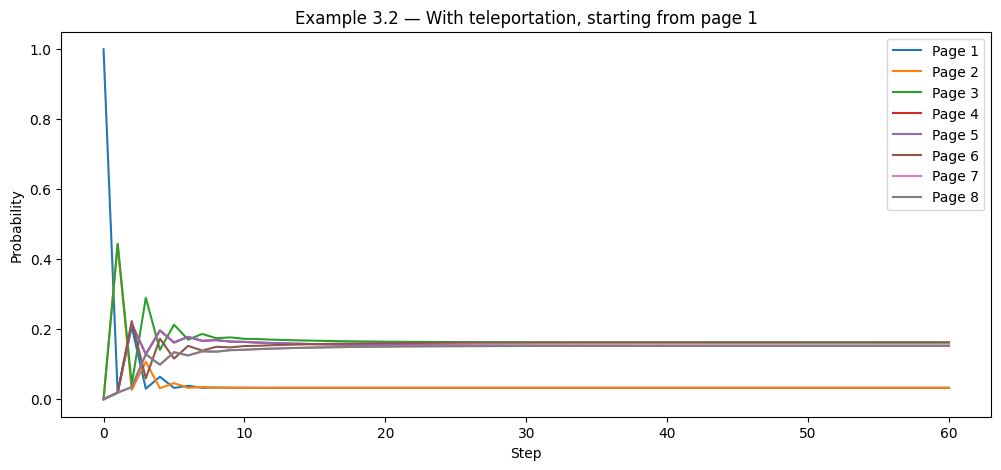

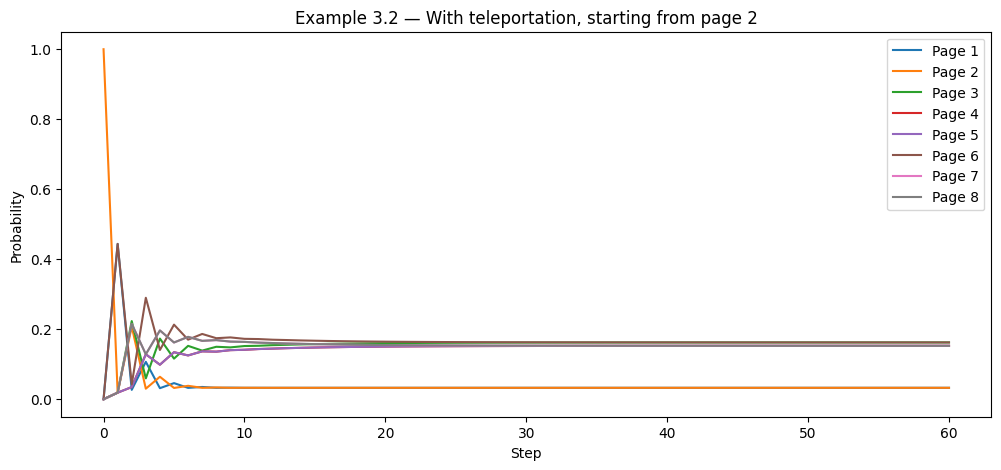

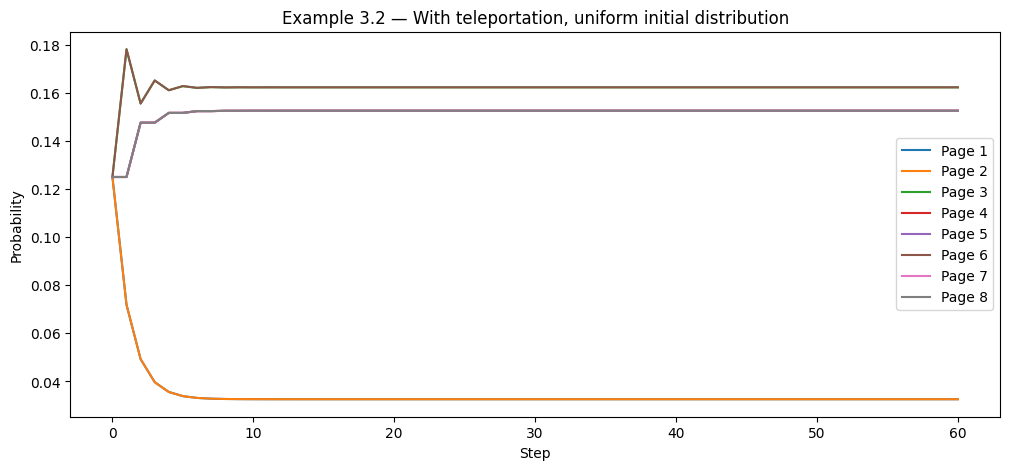

In [257]:
history_G_double1 = iterate_probabilities(
    G_double, x0_page1, 60,
    "Example 3.2 — With teleportation, starting from page 1"
)

history_G_double2 = iterate_probabilities(
    G_double, x0_page2, 60,
    "Example 3.2 — With teleportation, starting from page 2"
)

history_G_double_uniform = iterate_probabilities(
    G_double, x0_uniform, 60,
    "Example 3.2 — With teleportation, uniform initial distribution"
)

The distributions evolve differently at first but approach the same
limit. Teleportation allows probability to move between the groups
and return to pages 1 and 2.

We compare the final updates with the stationary distribution
computed from G_double.

In [258]:
comparison_G_double = pd.DataFrame({
    "Page": range(1, 9),
    "Start on page 1": history_G_double1[-1],
    "Start on page 2": history_G_double2[-1],
    "Uniform start": history_G_double_uniform[-1],
    "Stationary probability": pi_G_double
})

display(comparison_G_double.round(4))

,Page,Start on page 1,Start on page 2,Uniform start,Stationary probability
0,1,0.0326,0.0326,0.0326,0.0326
1,2,0.0326,0.0326,0.0326,0.0326
2,3,0.1623,0.1623,0.1623,0.1623
3,4,0.1526,0.1526,0.1526,0.1526
4,5,0.1526,0.1526,0.1526,0.1526
5,6,0.1623,0.1623,0.1623,0.1623
6,7,0.1526,0.1526,0.1526,0.1526
7,8,0.1526,0.1526,0.1526,0.1526


All three final distributions closely approximate the same stationary
distribution. Every page now has positive probability, and the two
symmetric groups receive equal total shares.

The limiting distribution no longer depends on the initial distribution.
This concerns probability updates: individual simulated paths remain
random and need not follow the same sequence of pages.

### 8) Random Surfing with Teleportation

We repeat four simulations using G_double, with the same starting
pages and seeds as before. Teleportation now allows each surfer
to leave either group and visit all eight pages.

We display the first 20 visits of each simulation side by side.

In [259]:
rng_start = np.random.default_rng(123)

paths_G_double = {}
frequencies_G_double_runs = {}

for run, seed in enumerate(seeds_double, start=1):
    start_page = rng_start.choice([1, 2])

    frequencies, path = random_surfer(
        G_double,
        n_visits=100000,
        seed=seed,
        show=False,
        start_page=start_page
    )

    name = f"Simulation {run}"
    paths_G_double[name] = path
    frequencies_G_double_runs[name] = frequencies

paths_table_G_double = pd.DataFrame(paths_G_double)
paths_table_G_double.index.name = "Time"

display(paths_table_G_double)

,Simulation 1,Simulation 2,Simulation 3,Simulation 4
Time,,,,
0,1,2,2,1
1,3,3,1,2
2,3,4,2,6
3,4,3,6,7
4,3,5,7,5
5,4,7,1,3
6,5,5,3,4
7,4,3,4,3
8,3,5,3,8


Neither group is closed anymore: entering one does not prevent
the surfer from leaving it later. A short displayed path need not
show every possible transition.

We compare the frequencies from all 100,000 visits in each simulation
with the unique stationary distribution of G_double.

In [260]:
simulation_G_double = pd.DataFrame({
    "Page": range(1, 9),
    **frequencies_G_double_runs,
    "Stationary probability": pi_G_double
})

display(simulation_G_double.round(4))

,Page,Simulation 1,Simulation 2,Simulation 3,Simulation 4,Stationary probability
0,1,0.0321,0.0329,0.0327,0.0332,0.0326
1,2,0.0317,0.0324,0.0325,0.0332,0.0326
2,3,0.1641,0.1640,0.1631,0.1623,0.1623
3,4,0.1566,0.1536,0.1538,0.1536,0.1526
4,5,0.1534,0.1534,0.1546,0.1526,0.1526
5,6,0.1595,0.1616,0.1619,0.1622,0.1623
6,7,0.1517,0.1516,0.1499,0.1511,0.1526
7,8,0.1508,0.1505,0.1514,0.1517,0.1526


All four simulations approximate the same stationary distribution,
with small differences due to the finite number of visits.

Without teleportation, each trajectory remained in one closed group
and approximated its group-specific stationary distribution.
With teleportation, each surfer can explore the whole network,
and its long-run frequencies approach the same unique distribution.

### 9) Conclusion of Example 3.2

Two closed, aperiodic groups allow probability updates to converge,
but the limiting distribution depends on the initial distribution.
A single surfer eventually stays in one group, so its visit frequencies
reflect that particular outcome.

Teleportation connects the groups and makes the matrix primitive.
There is then one strictly positive stationary distribution:
probability updates approach it from any initial distribution,
and long-run simulated visit frequencies approximate it as well.

## Example 4: Trapping and Periodic Alternation

In Example 3, probability settled within a closed group.
Here, the surfer becomes trapped in a pair of pages and must
keep moving back and forth between them.

Our six pages form a path leading to pages 5 and 6, which link
only to each other. Once the surfer enters this pair, it cannot
leave or stay on the same page.

We start the probability updates with all probability on page 1
to follow this movement clearly. We investigate why a stationary
distribution can exist even when the updates do not approach it,
and why visit frequencies can still settle.

Finally, we introduce teleportation to address both trapping
and persistent oscillation.

### 1) Matrix Creation, Network and Checking Primitivity

We construct P3 by linking each of pages 1–5 to the next page,
then linking page 6 back to page 5. Each column contains one entry
equal to one, so the next destination is certain.

As the graph plotted will show, this creates the path 1 → 2 → 3 → 4 → 5, followed by repeated
movement between pages 5 and 6. A return to either of these
two pages takes 2, 4, 6, ... steps: the closed group has period two.

We then call `check_primitivity` to check whether any power
of the matrix becomes strictly positive.

In [261]:
n = 6
P3 = np.zeros((n, n))

for j in range(n):
    if j < n - 1:
        destination = j + 1
    else:
        destination = n - 2

    P3[destination, j] = 1

print("Transition matrix:")
print(P3)


Transition matrix:
[[0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 1.]
 [0. 0. 0. 0. 1. 0.]]


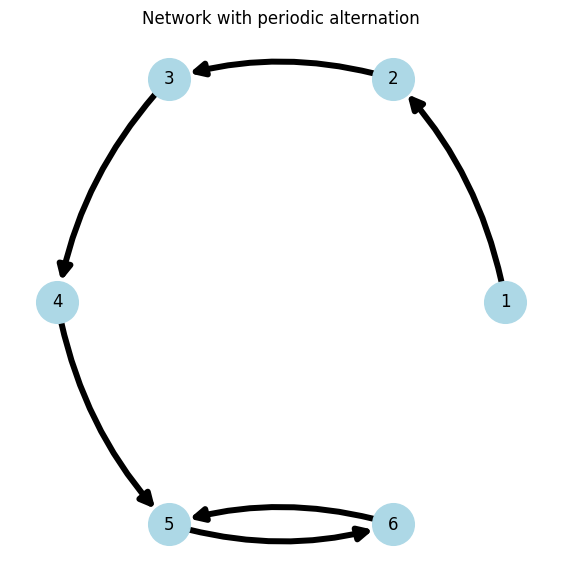

In [262]:
plot_network(P3, title="Network with periodic alternation")

In [263]:
check_primitivity(P3);


No strictly positive power found within 100 steps.
The matrix is not primitive.


P3 is not primitive. From pages 5 and 6, there is no route back
to pages 1–4, so the full network is reducible.

Within the closed pair, the destination also depends on whether
the number of steps is odd or even. Starting from page 5,
the surfer reaches page 6 after an odd number of steps and
page 5 after an even number.

The network therefore combines two obstacles: no escape from
the pair and a fixed rhythm of movement within it.

### 2) Eigenvalues and Stationary Distribution

We compute the eigenvalues of P3 and obtain the stationary
distribution from the eigenvector associated with +1.
We check whether this stationary balance also attracts
the probability updates.

In [264]:
eigenvalues3, pi3 = eigen_analysis(P3)


Eigenvalues:
[ 1. -1.  0.  0.  0.  0.]
Absolute values of eigenvalues:
[1. 1. 0. 0. 0. 0.]
Stationary distribution:
[0.  0.  0.  0.  0.5 0.5]


The stationary distribution assigns probability 0.5 to each
of pages 5 and 6, and zero to pages 1–4. Each update exchanges
the probabilities of the final two pages. Since these amounts
are equal, the stationary distribution remains unchanged.

However, two eigenvalues have modulus one: +1 and −1.
While +1 corresponds to the stationary distribution, −1 allows
a deviation from that balance to reverse sign at every update
without becoming smaller.

A stationary distribution therefore exists and is unique,
but probability updates need not converge to it. We now show
this by starting entirely on page 1.

### 3) Following the Probability Updates

We place all initial probability on page 1 and apply P3 for
20 steps. Since every page has exactly one destination,
we can follow the probability as it moves through the network.

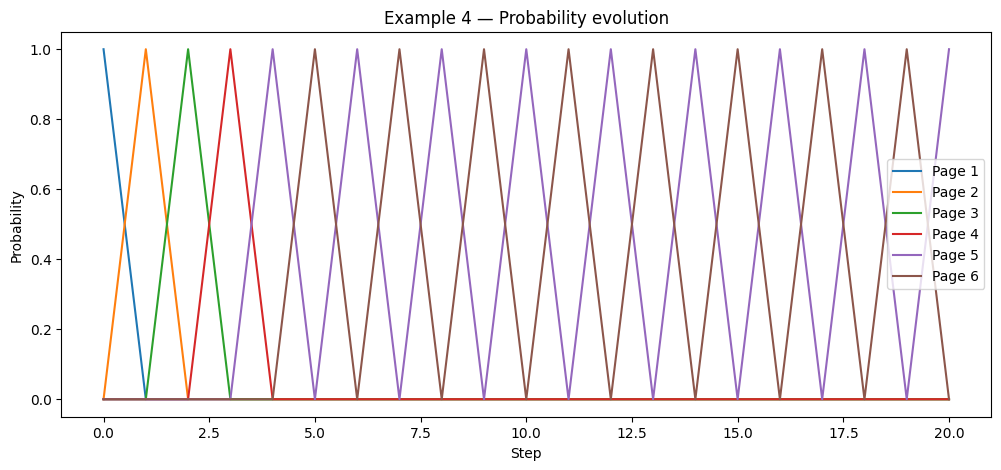

In [265]:
history3 = iterate_probabilities(
    P3, [1, 0, 0, 0, 0, 0], 20, "Example 4 — Probability evolution"
)


Probability moves through pages 1–4 and reaches page 5 at step 4.
It then switches between pages 5 and 6, with no possibility
of leaving the pair.

We compare four consecutive updates with the stationary
distribution to make this persistent alternation explicit.

In [266]:
comparison3 = pd.DataFrame({
    "Page": range(1, P3.shape[0] + 1),
    "Step 17": history3[17],
    "Step 18": history3[18],
    "Step 19": history3[19],
    "Step 20": history3[20],
    "Stationary distribution": pi3
})

comparison3.round(4)


,Page,Step 17,Step 18,Step 19,Step 20,Stationary distribution
0,1,0.0,0.0,0.0,0.0,0.0
1,2,0.0,0.0,0.0,0.0,0.0
2,3,0.0,0.0,0.0,0.0,0.0
3,4,0.0,0.0,0.0,0.0,0.0
4,5,0.0,1.0,0.0,1.0,0.5
5,6,1.0,0.0,1.0,0.0,0.5


Pages 1–4 have zero probability at every displayed step.
All probability remains inside the closed pair, but its allocation
keeps changing: page 5 has probability one at steps 18 and 20,
while page 6 has probability one at steps 17 and 19.

Neither sequence approaches 0.5. The stationary distribution
describes an equal split that would remain unchanged if we
started there; it does not mean that the updates must reach
that split.

Here, trapping determines where probability stays, while
periodicity prevents it from settling between the two pages.

### 4) Random Surfing and Visit Frequencies

We simulate 100,000 visits using P3 and display the first 20.
The starting page is selected randomly, but every subsequent
move is determined by the single outgoing link.

From any starting page, the surfer eventually reaches pages
5 and 6 and keeps alternating between them. We compare the
accumulated visit frequencies with the stationary distribution.

In [267]:
frequencies3, path3 = random_surfer(P3)


,Time,Page visited
0,0,1
1,1,2
2,2,3
3,3,4
4,4,5
5,5,6
6,6,5
7,7,6
8,8,5
9,9,6


In [268]:
simulation_comparison3 = pd.DataFrame({
    "Page": range(1, P3.shape[0] + 1),
    "Simulated frequency": frequencies3,
    "Stationary probability": pi3,
})

simulation_comparison3.round(4)


,Page,Simulated frequency,Stationary probability
0,1,0.0,0.0
1,2,0.0,0.0
2,3,0.0,0.0
3,4,0.0,0.0
4,5,0.5,0.5
5,6,0.5,0.5


Approximately half of all visits occur on page 5 and half on
page 6, matching the stationary distribution.

This does not contradict the earlier oscillations. The sequence
5, 6, 5, 6 keeps changing at every step, yet divides its visits
equally between the two pages. Any initial visits to pages 1–4
become negligible as the simulation grows.

Visit frequencies can therefore settle even when the probability
distribution at each step does not. We now introduce teleportation
to allow escape from the pair and make probability updates converge.

### 5) Applying Teleportation

With probability 0.85, the surfer follows the original link.
With probability 0.15, it chooses uniformly among all six pages,
including its current page.

This gives the surfer a way to leave the closed pair and breaks
the compulsory alternation between pages 5 and 6. We construct
G3 and check its primitivity.

In [269]:
G3 = google_matrix(P3)


Google matrix:
[[0.025 0.025 0.025 0.025 0.025 0.025]
 [0.875 0.025 0.025 0.025 0.025 0.025]
 [0.025 0.875 0.025 0.025 0.025 0.025]
 [0.025 0.025 0.875 0.025 0.025 0.025]
 [0.025 0.025 0.025 0.875 0.025 0.875]
 [0.025 0.025 0.025 0.025 0.875 0.025]]


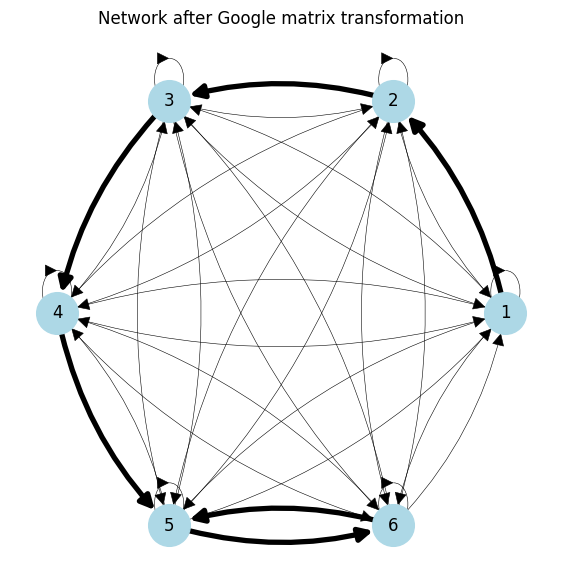

In [270]:
plot_network(G3, title="Network after Google matrix transformation")

In [271]:
check_primitivity(G3);


The matrix is primitive.
First strictly positive power: 1
[[0.025 0.025 0.025 0.025 0.025 0.025]
 [0.875 0.025 0.025 0.025 0.025 0.025]
 [0.025 0.875 0.025 0.025 0.025 0.025]
 [0.025 0.025 0.875 0.025 0.025 0.025]
 [0.025 0.025 0.025 0.875 0.025 0.875]
 [0.025 0.025 0.025 0.025 0.875 0.025]]


Every entry of G3 is positive, so the primitivity check succeeds
at the first power. The surfer can now reach any page directly
and can also remain where it is.

We next examine how these new possibilities change the eigenvalues
and the stationary distribution.

In [272]:
eigenvalues_G3, pi_G3 = eigen_analysis(G3)


Eigenvalues:
[ 1.  +0.j  0.  +0.j  0.  -0.j -0.  +0.j -0.  -0.j -0.85+0.j]
Absolute values of eigenvalues:
[1.0e+00 1.0e-04 1.0e-04 1.0e-04 1.0e-04 8.5e-01]
Stationary distribution:
[0.025  0.0462 0.0643 0.0797 0.4107 0.3741]


Before teleportation, both +1 and −1 had modulus one.
Now +1 is the only eigenvalue with modulus one, while −1
becomes −0.85.

The negative sign still allows alternation, but the modulus
below one makes its amplitude shrink with each update.
Oscillations therefore fade instead of continuing indefinitely.

The other four eigenvalues are theoretically zero. Small values
near zero in the output are numerical approximations and do
not change this conclusion.

The stationary distribution now gives positive probability
to every page. Pages 5 and 6 retain the largest shares because
of their links, but pages 1–4 are no longer excluded.
Probability updates converge to this new balance from any
initial distribution.

### 6) Following the Probability Updates with Teleportation

We again place all initial probability on page 1, now using G3.
We extend the updates to 45 steps to follow how the oscillations
gradually fade.


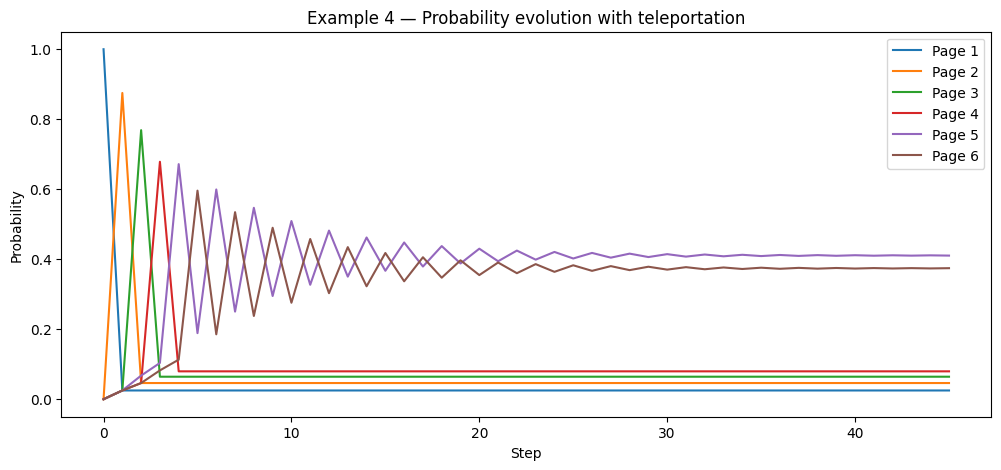

In [273]:
history_G3 = iterate_probabilities(
    G3, [1, 0, 0, 0, 0, 0], 45,
    "Example 4 — Probability evolution with teleportation"
)


Pages 5 and 6 still exchange probability, but the swings become
smaller over time. Meanwhile, pages 1–4 settle at positive values
instead of disappearing from the distribution.

The following table shows consecutive updates while the remaining
oscillations are still visible.

In [274]:
comparison_G3 = pd.DataFrame({
    "Page": range(1, n + 1),
    "Step 17": history_G3[17],
    "Step 18": history_G3[18],
    "Step 19": history_G3[19],
    "Step 20": history_G3[20],
    "Step 21": history_G3[21],
    "Step 22": history_G3[22],
    "Stationary distribution": pi_G3
})

comparison_G3.round(4)


,Page,Step 17,Step 18,Step 19,Step 20,Step 21,Step 22,Stationary distribution
0,1,0.0250,0.0250,0.0250,0.0250,0.0250,0.0250,0.0250
1,2,0.0462,0.0462,0.0462,0.0462,0.0462,0.0462,0.0462
2,3,0.0643,0.0643,0.0643,0.0643,0.0643,0.0643,0.0643
3,4,0.0797,0.0797,0.0797,0.0797,0.0797,0.0797,0.0797
4,5,0.3791,0.4375,0.3879,0.4301,0.3942,0.4247,0.4107
5,6,0.4056,0.3473,0.3969,0.3547,0.3906,0.3601,0.3741


For page 5, the values at steps 18, 20 and 22 fall from 0.4375
to 0.4301 to 0.4247, approaching 0.4107 from above.
For page 6, they rise from 0.3473 to 0.3547 to 0.3601,
approaching 0.3741 from below.

At the intervening steps, each probability approaches its
stationary value from the opposite side. The alternation remains,
but its amplitude decreases: the probabilities now move towards
a stable balance.

### 7) Random Surfing with Teleportation

We simulate 100,000 visits using G3 and display the first 20.
The surfer can now escape from pages 5 and 6, revisit earlier
pages, or remain on its current page.

We compare the accumulated visit frequencies with the new
stationary distribution.

In [275]:
frequencies_G3, path_G3 = random_surfer(G3)


,Time,Page visited
0,0,1
1,1,2
2,2,3
3,3,4
4,4,5
5,5,6
6,6,5
7,7,6
8,8,5
9,9,6


The displayed path moves through pages 1–4 and then alternates
between pages 5 and 6. This short sequence does not show an escape,
even though leaving the pair is now possible at every step.

All displayed moves are compatible with the original links,
so the path alone cannot tell us whether any involved teleportation.
The full simulation gives a broader picture.

In [276]:
simulation_comparison_G3 = pd.DataFrame({
    "Page": range(1, G3.shape[0] + 1),
    "Simulated frequency": frequencies_G3,
    "Stationary probability": pi_G3,
})

simulation_comparison_G3.round(4)


,Page,Simulated frequency,Stationary probability
0,1,0.0246,0.0250
1,2,0.0460,0.0462
2,3,0.0637,0.0643
3,4,0.0793,0.0797
4,5,0.4114,0.4107
5,6,0.3750,0.3741


The simulated frequencies closely match the stationary probabilities.
Pages 1–4 now receive about 21% of all visits, showing that they
are revisited rather than left behind permanently.

Page 5 has a higher stationary probability than page 6.
Both receive the same contribution from uniform teleportation,
but page 5 also receives probability through links from pages
4 and 6, whereas page 6 receives it only from page 5.

### 8) Conclusion of Example 4

The original network creates two obstacles. Probability cannot
escape from pages 5 and 6, and their compulsory alternation
prevents an unequal split from settling.

A stationary distribution still exists: placing half the probability
on each page gives a balance that remains unchanged. But starting
from page 1 produces an endless exchange between zero and one.
Visit frequencies nevertheless approach one half on each page,
because alternation divides visits equally over time.

Teleportation addresses both obstacles. It allows escape from
the pair and interrupts the fixed rhythm. Algebraically, −1
becomes −0.85, so oscillations shrink instead of persisting.

The corrected distribution converges and gives positive weight
to every page. Pages 5 and 6 remain prominent because of the
original links, but they no longer retain all probability.
The surfer keeps moving while the probability distribution settles.

## Example 5: Real Network Example (The Harvard500 Web Graph)

The previous examples used six pages to make each mechanism easy
to follow. We now study Harvard500, a dataset containing links
between 500 pages of the Harvard University website. The dataset accompanies Cleve Moler's *Numerical Computing with MATLAB* and is listed in the [SuiteSparse Matrix Collection](https://sparse.tamu.edu/MathWorks/Harvard500).

The questions remain the same: does the link matrix preserve
probability, does a stable ranking emerge, and do simulated visits
agree with the stationary distribution?

We first remove links from pages to themselves, consistently with
our modelling choice, and identify dangling pages. We then examine
the original matrix, correct the dangling columns, and introduce
teleportation.

With 500 pages, we summarize the results rather than plot every
page separately. We also compare convergence before and after
teleportation to see how it affects the number of updates needed.

### 1) Loading the Data

We load `harvard500.mat` using `scipy.io.loadmat`. The file must
be in the notebook's working directory.

The data contain a link matrix G and a list of page URLs, U.
An entry G_ij equal to one indicates a link from page j to page i,
following the same column convention as our previous examples.

We convert the sparse matrix into a NumPy array and extract
the URLs. We then print the number of pages, the number of links,
and the distinct matrix entries to inspect what we have loaded.

In [277]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    data = scipy.io.loadmat("harvard500.mat")

G_raw = data["G"].toarray().astype(float)
urls = [u[0][0] for u in data["U"]]

n_h = G_raw.shape[0]

print("Number of pages:", n_h)
print("Number of links (including self-links):", int(G_raw.sum()))
print("Distinct values in G:", np.unique(G_raw))

Number of pages: 500
Number of links (including self-links): 2636
Distinct values in G: [0. 1.]


### 2) Removing Links to the Same Page

A link from a page to itself appears on the diagonal of the link matrix. We set these entries to zero, consistently with the previous examples, and store the resulting matrix as A.

We print the number of links removed and the number remaining.


In [278]:
n_self = int(np.trace(G_raw))
A = G_raw.copy()
np.fill_diagonal(A, 0)
print("Links to the same page removed:", n_self)
print("Remaining links:", int(A.sum()))


Links to the same page removed: 73
Remaining links: 2563


We remove 73 links from pages to themselves, leaving 2,563 links
between different pages. We now examine how these links are
distributed across the network.

### 3) Counting Links and Identifying Dangling Pages

We count outgoing links by summing each column of A, and incoming
links by summing each row. The first count tells us how many
destinations a page offers; the second tells us how many pages
point to it.

Pages with no outgoing links are dangling pages: the surfer has
no next destination. We identify them after removing links to
the same page, since this may also create dangling pages.

All counts refer to the 500 recorded pages. The histogram groups
pages by their number of outgoing links, showing whether most
offer many destinations or only a few.

We report the number and share of dangling pages, the share
with at most five outgoing links, and the number with more
than fifty. These summaries show how unevenly links are
distributed.

We also report the largest outgoing and incoming link counts,
and identify the page receiving the most links by its number
and URL. Shares are displayed as proportions between zero and one.

Dangling pages: 124
Share of dangling pages: 0.248
Share with at most 5 outgoing links: 0.708
Pages with more than 50 outgoing links: 2
Maximum outgoing links: 103
Maximum incoming links: 195
Page with most incoming links: 1 http://www.harvard.edu


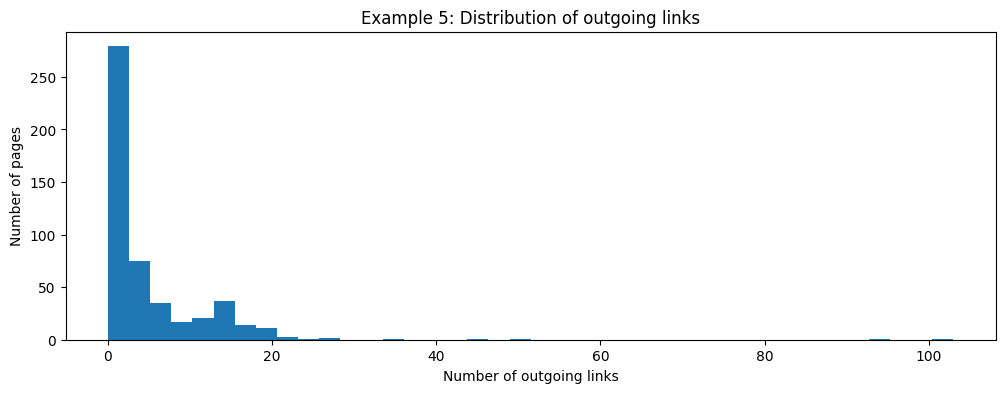

In [279]:
out_degree = A.sum(axis=0)
in_degree = A.sum(axis=1)
dangling = out_degree == 0
n_dangling = int(dangling.sum())
share_dangling = n_dangling / n_h
share_few_links = (out_degree <= 5).mean()
n_many_links = int((out_degree > 50).sum())
max_out_degree = int(out_degree.max())
most_linked_page = np.argmax(in_degree)
max_in_degree = int(in_degree[most_linked_page])

print("Dangling pages:", n_dangling)
print("Share of dangling pages:", round(share_dangling, 4))
print("Share with at most 5 outgoing links:", round(share_few_links, 4))
print("Pages with more than 50 outgoing links:", n_many_links)
print("Maximum outgoing links:", max_out_degree)
print("Maximum incoming links:", max_in_degree)
print("Page with most incoming links:", most_linked_page + 1,
      urls[most_linked_page])

plt.figure(figsize=(12, 4))
plt.hist(out_degree, bins=40)
plt.xlabel("Number of outgoing links")
plt.ylabel("Number of pages")
plt.title("Example 5: Distribution of outgoing links")
plt.show()


Most pages have few outgoing links: 70.8% have at most five,
including 124 dangling pages, or 24.8% of the network.
Only two pages have more than 50 outgoing links.

The Harvard homepage receives the most incoming links, with 195.
However, the ranking will depend also on which pages supply
those links, not just their number.

The dangling problem from Example 2 is therefore widespread here:
we need a rule that allows the surfer to continue from these pages.

### 4) Building the Link Transition Matrix

We turn the recorded links into transition probabilities.
For each page with outgoing links, we divide its column in A
by the number of destinations. A page with four links, for example,
assigns probability 1/4 to each.

Dangling columns remain zero for now, allowing us to examine
the uncorrected model before introducing a solution.

We count how many columns sum to one and how many remain zero,
rather than displaying all 500 column sums.

Given the big amount of pages we avoid plotting the network.

In [280]:
P4 = np.zeros((n_h, n_h))

for j in range(n_h):
    if out_degree[j] > 0:
        P4[:, j] = A[:, j] / out_degree[j]

column_sums = P4.sum(axis=0).round(10)

print('Columns summing to one:', int((column_sums == 1).sum()))
print('Columns summing to zero:', int((column_sums == 0).sum()))


Columns summing to one: 376
Columns summing to zero: 124


There are 376 columns summing to one and 124 summing to zero.
P4 therefore does not preserve total probability: any mass
on a dangling page disappears at the next update, just as
in Example 2.

### Visualizing the Original Network

We display the original network before any correction. Each node represents a page, and each line
represents an existing link in P4.

All nodes have the same size. Arrowheads and page labels are omitted
for readability, although the underlying network is directed.
Positions only serve to arrange the network visually.

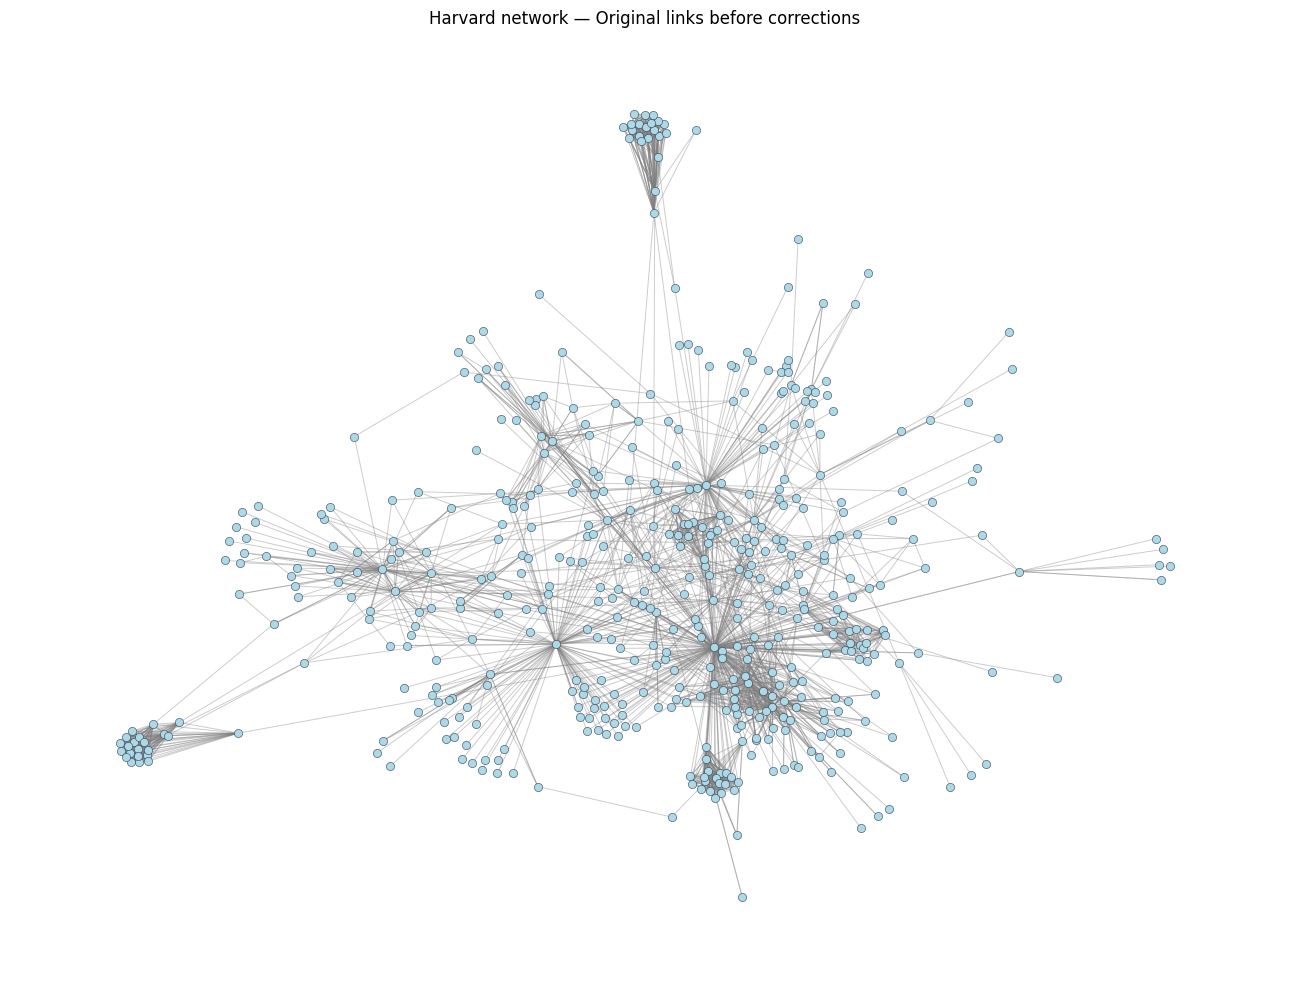

In [281]:
original_network = nx.from_numpy_array(
    (P4.T > 0).astype(int),
    create_using=nx.DiGraph
)

positions_original = nx.spring_layout(
    original_network.to_undirected(),
    seed=123,
    iterations=100
)

plt.figure(figsize=(13, 10))

nx.draw_networkx_edges(
    original_network,
    pos=positions_original,
    arrows=False,
    edge_color="grey",
    width=0.7,
    alpha=0.40
)

nx.draw_networkx_nodes(
    original_network,
    pos=positions_original,
    node_color="lightblue",
    node_size=35,
    edgecolors="#334155",
    linewidths=0.4
)

plt.title("Harvard network — Original links before corrections")
plt.axis("off")
plt.tight_layout()
plt.show()

### 5) Checking Primitivity

We apply `check_primitivity` to P4, searching for a strictly
positive power within 100 steps.

In [282]:
check_primitivity(P4);


No strictly positive power found within 100 steps.
The search limit is insufficient to conclude.


The function finds no strictly positive power. For a matrix
of this size, the search limit alone is insufficient to conclude.

However, we already know that P4 contains zero columns.
These remain zero in every positive power, so P4 cannot be
primitive. No further powers need to be checked.

### 6) Eigenvalues and Stationary Distribution

Dangling pages cause probability loss, but does all probability
eventually disappear? We examine the largest eigenvalue modulus
to determine what repeated updates will do.

We use `eigen_analysis` with `show=False` and display only
the largest modulus and whether a stationary distribution
was found.

In [283]:
eigenvalues4, pi4 = eigen_analysis(P4, show=False)

print('Largest modulus of the eigenvalues of P4:',
      np.abs(eigenvalues4).max().round(4))
print('Stationary distribution:', pi4)


Largest modulus of the eigenvalues of P4: 0.9332
Stationary distribution: None


The largest modulus is 0.9332, so all eigenvalues lie strictly
below one in modulus. There is no eigenvalue +1 and therefore
no stationary probability distribution, reported as None.

Repeated updates eventually send all page values to zero.
In this network, the dangling pages ultimately drain all
probability. We next follow the total remaining mass over time.

### 7) Following the Probability Updates

We start with equal probability on all 500 pages. At each step,
we add the values assigned to all pages to obtain the total
remaining probability:

$$
m_t = \sum_{i=1}^{500} x_{t,i}.
$$

For a stochastic matrix, this sum stays equal to one: all
probability is passed from one page to another. Here, dangling
pages do not pass it on, so some mass disappears at each update.

We track this total over 50 steps. A single curve makes the
overall loss easier to see than 500 separate page curves.

We use `total=True` to plot this sum and print its value after
1, 10 and 50 updates, showing the initial loss and how much
probability remains later.

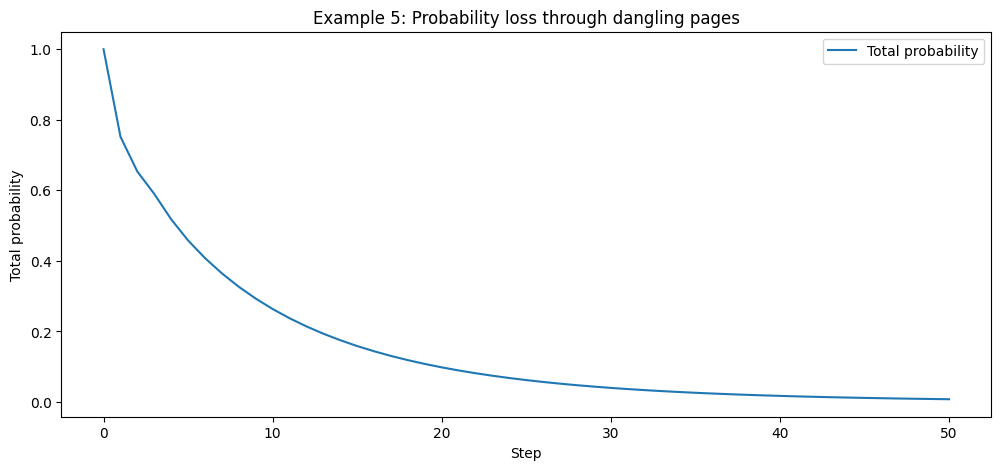

Total probability after 1 step: 0.752
Total probability after 10 steps: 0.2635
Total probability after 50 steps: 0.0078


In [284]:
x0_h = np.ones(n_h) / n_h
history4 = iterate_probabilities(
    P4, x0_h, 50,
    "Example 5: Probability loss through dangling pages", total=True
)
total_probability = history4.sum(axis=1)
print("Total probability after 1 step:", total_probability[1].round(4))
print("Total probability after 10 steps:", total_probability[10].round(4))
print("Total probability after 50 steps:", total_probability[50].round(4))


The total probability decreases instead of remaining equal to one.
After the first update, it falls to 0.752 because the probability
initially assigned to the 124 dangling pages is lost.

Further updates carry more probability to dangling pages, where
it disappears. This agrees with the eigenvalue analysis: the
largest modulus is below one, so the remaining mass tends to zero.

We therefore need to provide a destination from dangling pages
to preserve probability and allow the surfer to keep moving.

### 8) Random Surfing and Visit Frequencies

We now try to simulate visits using P4, as in the previous
examples, to compare observed visit frequencies with the
matrix analysis.

Before generating a path, the function checks whether each
column provides valid transition probabilities.


In [285]:
random_surfer(P4);


The simulation cannot start: P must be column-stochastic.
Entries must be nonnegative and each column must sum to one.


### 9) Correcting Dangling Pages

As in Example 2, we replace each of the 124 zero columns with
uniform probabilities of 1/500. Whenever the surfer reaches
a dangling page, it can therefore move to any page, including
the current one.

We call the corrected matrix S4, check its column sums,
and test whether it is primitive.

We suppress the full matrix output and display only whether
all column sums are numerically close to one and the first
power with all entries strictly positive.

In [286]:
S4 = correct_dangling(P4, show=False)
print("All columns sum to one:", np.allclose(S4.sum(axis=0), 1))
k_S4, _ = check_primitivity(S4, show=False)
print("First strictly positive power:", k_S4)


All columns sum to one: True
First strictly positive power: 6


All columns now sum to one, so probability is preserved.
The sixth power of S4 is strictly positive: as in Example 2,
the dangling correction alone makes this network primitive.

We now compute its eigenvalues and stationary distribution.
We save the results for the following comparisons without
printing all 500 values.

In [287]:
eigenvalues_S4, pi_S4 = eigen_analysis(S4, show=False)


Since S4 is stochastic and primitive, it has a unique, positive
stationary distribution, which probability updates approach
from any initial distribution.

Teleportation is therefore not necessary for convergence here.
We introduce it next to investigate how it changes convergence
speed and the ranking.

### 10) Applying Teleportation

The dangling correction already makes S4 stochastic and primitive,
so a unique, positive stationary distribution exists and probability
updates converge to it. As in Example 2, no further correction is
needed to obtain these properties.

Here, we investigate an additional question: can teleportation
make convergence faster? We construct G4 with alpha = 0.85.
At each step, the surfer uses the transitions in S4 with probability
0.85 and chooses uniformly among all 500 pages with probability 0.15.

We check primitivity and compute the new stationary distribution.
Teleportation also changes the ranking, so each matrix will be
compared with its own stationary distribution.

In [288]:
G4 = google_matrix(S4, alpha=0.85)
k_G4, _ = check_primitivity(G4, show=False)
print("First strictly positive power:", k_G4)
eigenvalues_G4, pi_G4 = eigen_analysis(G4, show=False)


Google matrix:
[[0.0003 0.2128 0.0711 ... 0.2128 0.0003 0.0003]
 [0.033  0.0003 0.0003 ... 0.0003 0.0003 0.0003]
 [0.033  0.0003 0.0003 ... 0.0003 0.0003 0.0003]
 ...
 [0.0003 0.0003 0.0003 ... 0.0003 0.0003 0.0003]
 [0.0003 0.0003 0.0003 ... 0.0003 0.0003 0.0003]
 [0.0003 0.0003 0.0003 ... 0.0003 0.0003 0.0003]]
First strictly positive power: 1


G4 is strictly positive, so the primitivity check succeeds
at the first power. Every page can now be reached directly
from every other page.

Both S4 and G4 guarantee convergence. To understand how their
convergence speeds differ, we now compare their eigenvalues.

#### Comparing Convergence through Eigenvalues

Both S4 and G4 converge to their own stationary distributions.
We now examine whether teleportation changes the speed of
this convergence.

The eigenvalue +1 preserves the stationary distribution.
Among the remaining eigenvalues, the largest modulus indicates
how slowly deviations from equilibrium can decay. This is
the second largest modulus overall: a smaller value means
faster asymptotic convergence.

We extract this value from the eigenvalues already computed
and print it for both matrices.

In [289]:
second_S4 = np.sort(np.abs(eigenvalues_S4))[-2]
second_G4 = np.sort(np.abs(eigenvalues_G4))[-2]
print("Second largest modulus of S4:", second_S4.round(4))
print("Second largest modulus of G4:", second_G4.round(4))


Second largest modulus of S4: 0.9214
Second largest modulus of G4: 0.7832


The second largest modulus falls from 0.9214 to 0.7832.
Teleportation multiplies every eigenvalue other than +1
by 0.85, making deviations from equilibrium decay faster
in the long run.

We next examine the probability updates to measure how many
steps each matrix needs to approach its own stationary
distribution to the same accuracy.

#### Eigenvalues in the Complex Plane (Without Dangling Correction, With Dangling Correction, and With Teleportation)

To have a useful visualization of the 500 eigenvalues and how they appear with the different adjustments, we plot them in the complex plane together with the unit circle.

- For P4, all eigenvalues lie strictly inside the unit circle:
  there is no eigenvalue +1.
- For S4, the eigenvalue +1 appears, while the others remain inside
  the circle, some of them close to its boundary.
- For G4, all eigenvalues other than +1 are contracted towards the
  origin and lie inside the circle of radius 0.85 (dashed).


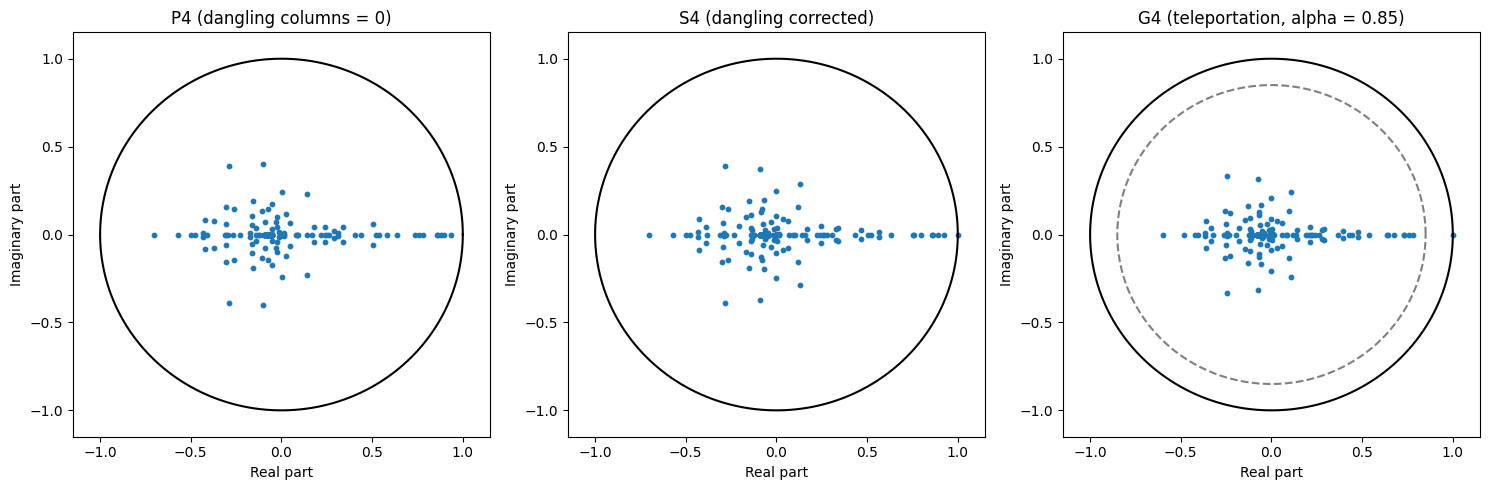

In [290]:
angles = np.linspace(0, 2 * np.pi, 400)

f, ax = plt.subplots(1, 3, figsize=(15, 5))

all_eigenvalues = [eigenvalues4, eigenvalues_S4, eigenvalues_G4]
titles = ['P4 (dangling columns = 0)', 'S4 (dangling corrected)',
          'G4 (teleportation, alpha = 0.85)']

for i in range(3):
    ax[i].plot(np.cos(angles), np.sin(angles), color='black')
    ax[i].scatter(all_eigenvalues[i].real, all_eigenvalues[i].imag, s=10)
    ax[i].set(title=titles[i], xlabel='Real part', ylabel='Imaginary part')
    ax[i].set_xlim(-1.15, 1.15)
    ax[i].set_ylim(-1.15, 1.15)

ax[2].plot(0.85 * np.cos(angles), 0.85 * np.sin(angles), '--', color='grey')

plt.tight_layout()
plt.show()

### 11) Following the Probability Updates

Both S4 and G4 preserve total probability, so its sum remains
one. To study convergence, we instead measure the distance
from each matrix's stationary distribution:

$$
d_t = \sum_{i=1}^{500} |x_{t,i} - \pi_i|.
$$

We add the absolute differences across all pages, preventing
positive and negative differences from cancelling out.
A smaller distance means that the distribution is closer
to equilibrium.

We start from the same uniform distribution and compute
300 updates for each matrix. The graph shows the first
100 steps, with one curve for S4 and one for G4.

We also print the distance after 10 updates and the first
step at which it falls below 10⁻⁸. This common tolerance
allows us to compare the number of updates needed to reach
the same accuracy.

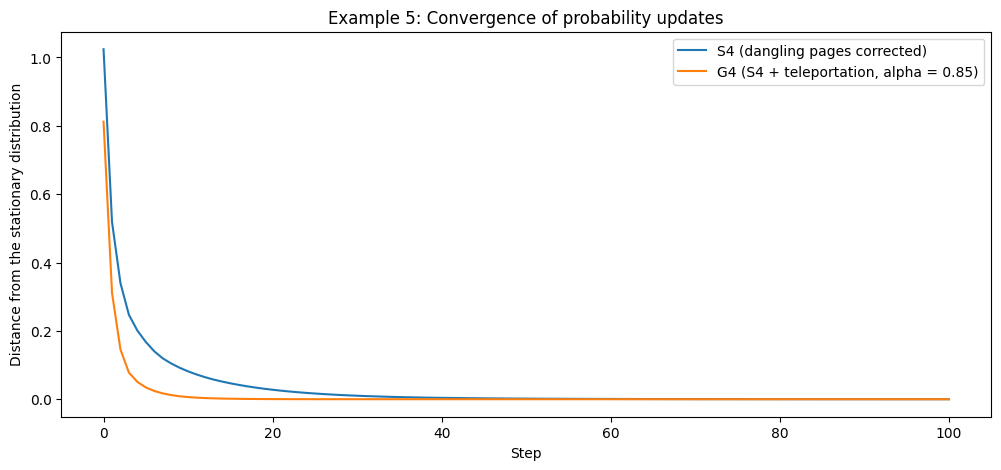

Distance after 10 steps - S4: 0.0815  G4: 0.0062
S4 - first step with distance below 1e-8: 198
G4 - first step with distance below 1e-8: 62


In [291]:
n_steps_h = 300
tolerance = 1e-8
x0_h = np.ones(n_h) / n_h

history_S4 = iterate_probabilities(S4, x0_h, n_steps_h, plot=False)
history_G4 = iterate_probabilities(G4, x0_h, n_steps_h, plot=False)

distance_S4 = np.abs(history_S4 - pi_S4).sum(axis=1)
distance_G4 = np.abs(history_G4 - pi_G4).sum(axis=1)

plt.figure(figsize=(12, 5))
plt.plot(distance_S4[:101], label='S4 (dangling pages corrected)')
plt.plot(distance_G4[:101], label='G4 (S4 + teleportation, alpha = 0.85)')
plt.xlabel('Step')
plt.ylabel('Distance from the stationary distribution')
plt.title('Example 5: Convergence of probability updates')
plt.legend()
plt.show()

print('Distance after 10 steps - S4:', distance_S4[10].round(4),
      ' G4:', distance_G4[10].round(4))

for t in range(n_steps_h + 1):
    if distance_S4[t] < tolerance:
        print('S4 - first step with distance below 1e-8:', t)
        break

for t in range(n_steps_h + 1):
    if distance_G4[t] < tolerance:
        print('G4 - first step with distance below 1e-8:', t)
        break


Both distributions approach their respective stationary values,
but convergence is faster with teleportation. After 10 updates,
the distance is 0.0815 for S4 and 0.0062 for G4.

S4 reaches a distance below 10⁻⁸ after 198 updates, while G4
requires 62. For this initial distribution and tolerance,
teleportation therefore reduces the number of updates needed.
This agrees with the decrease in the second largest eigenvalue
modulus from 0.9214 to 0.7832.

The curves start at different heights because the same initial
distribution is compared with two different stationary
distributions. Neither curve measures probability loss:
both matrices preserve total probability throughout.

### 12) Random Surfing and Visit Frequencies

The previous section followed entire probability distributions. We now simulate a single surfer on G4 to check whether visit frequencies approximate its stationary distribution.

We simulate 1,000,000 visits and display the first 20 visited pages with their URLs. Frequencies use the full simulation. With `show=False`, we suppress the default path table and display only the version with URLs; `urls[p - 1]` matches page numbers to the list's zero-based indices.


In [292]:
frequencies4, path4 = random_surfer(G4, n_visits=1000000, seed=123, show=False)

trace4 = pd.DataFrame({
    'Time': range(len(path4)),
    'Page visited': path4,
    'URL': [urls[p - 1] for p in path4]
})

trace4


,Time,Page visited,URL
0,0,8,http://www.fas.harvard.edu
1,1,1,http://www.harvard.edu
2,2,8,http://www.fas.harvard.edu
3,3,23,http://www.news.harvard.edu/gazette/2003/01.30...
4,4,26,http://www.news.harvard.edu/gazette/calendar
5,5,260,http://search.harvard.edu:8765/query.html
6,6,245,http://www.radcliffe.edu/news/pr/030128_david....
7,7,230,http://www.radcliffe.edu/contacts/index.html
8,8,240,http://www.radcliffe.edu/events/index.html
9,9,241,http://www.radcliffe.edu/murray/index.html


#### Comparing Visit Frequencies and Stationary Probabilities

We compare the simulated visit frequency of each page with
its stationary probability under G4.

With 500 pages, displaying the full table would be overwhelming. The top ten pages are of greatest interest, since they receive the most visits and have the largest stationary probabilities so we display them together with their URLs and their numbers of incoming and outgoing links in the recorded network.

We also report the largest absolute difference between
simulated frequency and stationary probability across all
500 pages, so the comparison is not limited to the displayed rows.


In [293]:
simulation_comparison4 = pd.DataFrame({
    'Page': range(1, n_h + 1),
    'Simulated frequency': frequencies4,
    'Stationary probability': pi_G4,
    'Incoming links': in_degree.astype(int),
    'Outgoing links': out_degree.astype(int),
    'URL': urls
})

simulation_comparison4 = simulation_comparison4.sort_values(
    'Stationary probability', ascending=False
)

print('Largest absolute difference over all pages:',
      np.abs(frequencies4 - pi_G4).max().round(5))

simulation_comparison4.head(10).round(4)


Largest absolute difference over all pages: 0.00045


,Page,Simulated frequency,Stationary probability,Incoming links,Outgoing links,URL
0,1,0.0842,0.0843,195,26,http://www.harvard.edu
9,10,0.0162,0.0167,21,18,http://www.hbs.edu
41,42,0.0165,0.0166,42,0,http://search.harvard.edu:8765/custom/query.html
129,130,0.0163,0.0163,24,12,http://www.med.harvard.edu
17,18,0.0141,0.0139,45,46,http://www.gse.harvard.edu
14,15,0.0130,0.0131,16,49,http://www.hms.harvard.edu
8,9,0.0116,0.0114,21,27,http://www.ksg.harvard.edu
16,17,0.0113,0.0111,13,6,http://www.hsph.harvard.edu
45,46,0.0099,0.0100,18,21,http://www.gocrimson.com
12,13,0.0085,0.0086,9,1,http://www.hsdm.med.harvard.edu


The simulated visit frequencies approximate the stationary
distribution. The largest absolute difference across all
500 pages is 0.00045. The remaining differences reflect
the finite number of simulated visits.

The Harvard homepage ranks first, with a stationary probability
of about 0.0843. Under this model, it receives approximately
8.43% of visits in the long run.

The ranking does not simply follow the number of incoming links.
Page 10 ranks above page 18 despite having 21 incoming links
rather than 45. The contribution of a link also depends on
the stationary probability of its source page and how many
outgoing links that source has.

Page 42 ranks third despite having no recorded outgoing links.
A dangling page can still receive many visits; the dangling
correction provides destinations from which the surfer can
continue its journey.

### 13) Conclusion of the Real Network Example

The Harvard500 network brings together the issues studied
in the smaller examples. After removing links to the same page,
124 pages have no outgoing links. The resulting matrix P4
loses probability, and its largest eigenvalue modulus is
below one, so repeated updates eventually send all remaining
mass to zero. The random surfer function rejects this matrix
before starting the simulation.

Correcting the dangling columns produces the column-stochastic
matrix S4. In this network, the correction also makes the
matrix primitive, ensuring a unique positive stationary
distribution and convergence from any initial distribution.

Teleportation is therefore not needed to obtain convergence
here, but it accelerates it. Starting from the uniform
distribution, G4 reaches a distance below $10^{-8}$ from
its own stationary distribution after 62 updates, compared
with 198 for S4.

Finally, simulated visit frequencies approximate the stationary
probabilities of G4. The resulting ranking places the Harvard
homepage first and illustrates that a page's importance depends
on the network of links, not only on its number of incoming links.